# Speech feature extraction: notes and experiments
### Librosa · Praat (through Parselmouth) · openSMILE eGeMAPSv02

This notebook studies how acoustic features of speech are measured and how far they can be trusted. It has two experiments:

| Part | Question | Data used |
|---|---|---|
| **Experiment 1** — one speaker | How do pitch, intensity, voicing, voice quality and spectral features vary during one utterance, and how much of that variation survives when it is summarised into a feature vector? | Librosa's `libri1` — one man reading, 14.84 s |
| **Experiment 2** — conversation | What acoustic differences can be observed between consecutive speakers' turns, and what other factors might explain them? | `R1_pyannote` — two speakers, 30 s, annotated turns |

**Goals**
1. Interpret the feature table — what 8 real eGeMAPS columns measure, their units, LLD vs functional, and when a value is unreliable.
2. Run a small descriptive conversation experiment — measure each turn, compare neighbouring turns, list alternative explanations.

**Scope**
- This is acoustic description only. Acoustic measurements alone cannot tell emotion, personality, honesty or confidence.
- No model is trained and no causal or predictive claims are made.

**How mistakes are recorded**
- The notebook was run twice. In run 1 several settings were wrong for this speaker.
- Every original cell is kept. Where something was corrected, the notes follow this order: **Attempt 1 (initial assumption) → Mistake realised → Correction made → Change noticed → New interpretation.**
- Cells marked `# FIX:` in code had small API fixes; cells marked `(new)` were added later.

| Section | Content |
|---|---|
| A | Study notes: openSMILE, feature sets, LLDs vs functionals |
| 1–2 | Setup, loading and listening |
| 3 | Waveform and spectrogram |
| 4 | Praat analysis: pitch, intensity, formants, harmonicity, jitter and shimmer |
| 5 | openSMILE feature extraction |
| 6 | Interpreting the feature table |
| 7 | Reliability checks and limitations |
| 8 | Two-speaker conversation experiment |
| 9 | Results, corrections log and conclusions |
| 10 | Exports |

# A. Study notes

## A1. openSMILE in one picture

**openSMILE:** a feature-extraction pipeline for audio.
- Input: a speech recording.
- Output: numbers (features) describing acoustic properties of the voice, used in research or machine learning.

| Step | Idea | What it decides |
|---|---|---|
| 1 | **Process signal** | Load and process the audio waveform |
| 2 | **Feature set** (e.g. eGeMAPS) | Which acoustic measurements to extract |
| 3 | **LLDs and functionals** | Measure properties over time, then summarise them |

- This is a conceptual pipeline; the exact processing steps depend on the selected configuration.

### A1.1 Process signal — how audio reaches the extractor

- **Signal** = a representation of something that changes over time.
- **Digital audio** = sound stored as a sequence of numbers called **samples**, e.g. `[0.01, 0.08, 0.15, 0.04, -0.07, ...]`.
- Each number is the waveform's **amplitude** (how far the pressure wave is from rest) at one instant.
- **Sampling rate** (Hz) = how many samples are stored per second.

General openSMILE process:
1. **Input** — an audio file, commonly WAV (in Python: a NumPy array plus its sampling rate).
2. **Read the signal** — the samples and the sampling rate.
3. **Frame the signal** — cut the audio into short, often overlapping windows.
4. **Calculate acoustic measurements** per frame — pitch-related, loudness-related and spectral measures.
5. **Output features** — measurements over time, or one summary vector per recording, depending on the configuration.

### A1.2 Why divide audio into frames?

- Speech changes constantly. One average over a 10 s recording could hide a quiet opening, a loud middle and a long pause.
- **Frame** = a short analysis window, e.g. **25 ms** long, moved forward every **10 ms** (the **hop** or time step). Overlapping frames give a smooth time series.

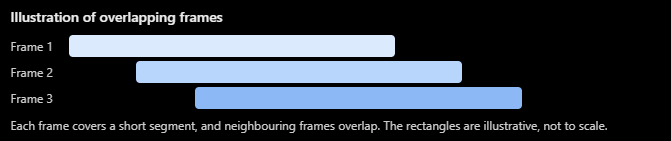

- The openSMILE configuration defines the framing; the audio is not split manually.
- openSMILE does **not** understand words. It extracts acoustic features from the sound only.

## A2. Feature sets — what is eGeMAPS?

- **Feature set** = a predefined collection of measurements openSMILE knows how to calculate, plus how to process them.
- A voice has hundreds of measurable properties; a feature set fixes *which* ones and *how*, so results are comparable across studies.

| Feature set | Notes |
|---|---|
| `GeMAPS` | **Ge**neva **M**inimalistic **A**coustic **P**arameter **S**et — a compact set designed for voice and affective-computing research. |
| `eGeMAPS` | **e**xtended GeMAPS — an expanded set for voice characteristics relevant to emotion and related paralinguistic analysis. (**Paralinguistic** = *how* something is said, not *what* is said.) |
| `ComParE_2016` | A much larger set with thousands of summary features. |

- The GeMAPS/eGeMAPS authors aimed for a **systematic, interpretable** set rather than as many numbers as possible (openSMILE documentation; Eyben et al., 2016, *IEEE Transactions on Affective Computing*).

### A2.1 What eGeMAPS measures — four families

**1. Pitch and voicing**
- Fundamental frequency (F0), pitch variation, and whether the vocal folds are vibrating (voicing).
- Describes **pitch level** and **intonation patterns**.

**2. Energy and loudness**
- The signal's energy and its perceived intensity.
- Describes **changes in vocal intensity**.

**3. Spectral characteristics**
- How energy is spread across frequencies: **spectral balance** (low vs high frequency energy) and **spectral flux** (how fast the spectrum changes between frames).
- Describes changes in **voice quality** and **articulation**.

**4. Voice quality**
- Cycle-to-cycle variation (jitter, shimmer) and the harmonic structure of voiced speech (e.g. harmonics-to-noise ratio).
- Describes **vocal stability** and **phonation** (how the vocal folds vibrate).

> These measurements describe acoustic properties. They do **not** directly measure emotions, honesty, confidence or personality.

### A2.2 How many features?

- In the current openSMILE Python documentation, **`eGeMAPSv02` gives 25 LLD streams and 88 functionals**. Older versions can differ.
- The run matched this: 25 LLDs and 88 functionals (Section 5).

## A3. LLDs vs functionals — measurements over time vs summaries

- **LLD (Low-Level Descriptor)** = a measurement calculated **frame by frame** as the audio progresses. Output: a time series.
- **Functional** = a **summary statistic** (mean, percentile, standard deviation, slope, …) of an LLD over a chosen segment — a whole recording, an utterance or one speaker turn. Output: one number per LLD per statistic.

**Worked example — pitch.** Someone says *"I really like this!"*; their pitch changes over time:

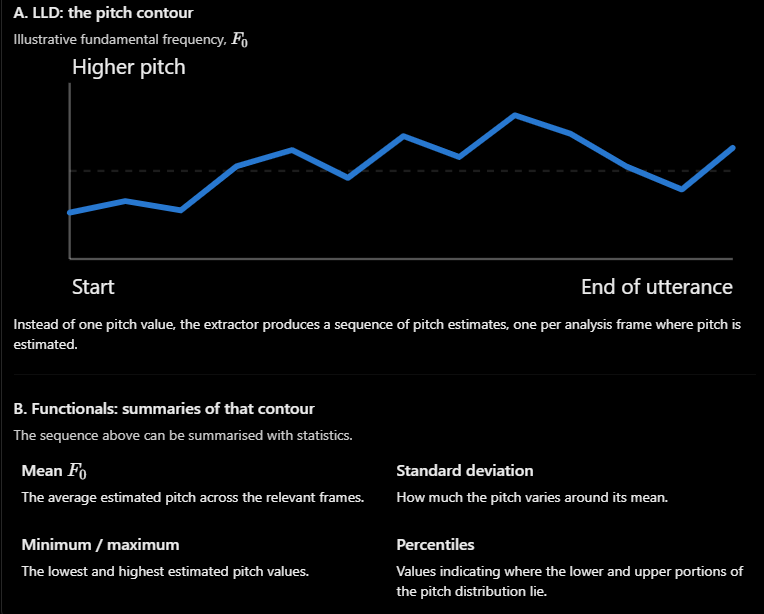

- The statistics in this figure are examples of summary statistics, not a list of what every eGeMAPS version includes.

### A3.1 Comparing the two outputs (for a 5 s recording)

| | LLD output | Functionals output |
|---|---|---|
| Shape | A sequence of values over time | A fixed set of summary values |
| Example | Pitch at successive frames | Mean pitch and pitch variability |
| Preserves timing? | Yes, when frame timestamps are kept | Generally no |
| Useful for | Studying changes throughout speech | A fixed-size vector for a conventional ML model |

- The LLD sequence can have **hundreds of frame-level values**; functionals compress them into **a few numbers**.
- Two utterances can have similar average pitch but very different contours. The average alone hides whether pitch rose, fell or fluctuated.
- The same applies to loudness, spectral and other descriptors. Functionals give a **fixed-dimensional** representation (same vector length for any recording length).
- Section 6.2 shows this with the output of this run.

# 1. Setup

In [ ]:
%pip install -q opensmile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 19.4 MB/s eta 0:00:00


In [ ]:
%pip install -q librosa soundfile numpy pandas matplotlib opensmile praat-parselmouth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 81.6 MB/s eta 0:00:00


**Libraries used**

| Library | Role |
|---|---|
| `librosa` | Sample speech recording; loading audio files |
| `soundfile` | Reading and writing audio files |
| `opensmile` | Standardised acoustic features (eGeMAPS) |
| `praat-parselmouth` | Praat's analyses from Python — no Praat desktop app needed |
| `numpy`, `pandas` | Numbers and tables |
| `matplotlib` | Plots |

- **Parselmouth** runs Praat's own analysis engine in Python.

# 2. Audio loading and listening

## Experiment 1 — one speaker, one utterance

**Research question:** How do pitch, vocal intensity, voicing, voice quality and spectral characteristics vary during a speech recording, and how much of that variation is retained when the recording is summarised into a feature vector?

| Topic | Measurement | Caution |
|---|---|---|
| Pitch and intonation | F0 over time (Praat pitch contour) | The pitch range setting matters |
| Intensity and pauses | Intensity contour, low-energy regions | Low energy ≠ silence |
| Voice quality and spectral structure | Jitter, shimmer, harmonicity, formants, spectral balance | Only where the signal supports reliable estimation |
| LLDs vs functionals | openSMILE time series vs eGeMAPS summary | Summaries lose temporal order |

- **Sample:** LibriSpeech example `libri1` from Librosa — natural read speech by one speaker.
- **Consistency rule:** every tool in Experiment 1 analyses the **same** mono array `audio` at its **original** `sample_rate`.

**References used**
- openSMILE Python: [usage guide](https://audeering.github.io/opensmile-python/usage.html) · [feature levels](https://audeering.github.io/opensmile-python/api/opensmile.FeatureLevel.html)
- Praat manual: [introductory tutorial](https://praat.org/manual/Intro) · [voice analysis](https://praat.org/manual/Voice)
- Parselmouth: [API reference](https://parselmouth.readthedocs.io/en/stable/api_reference.html)
- Librosa: [example recordings](https://librosa.org/doc/latest/recordings.html)

In [ ]:
import librosa
import soundfile as sf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import parselmouth
import opensmile

from IPython.display import Audio, display

print("Librosa:", librosa.__version__)
print("Parselmouth:", parselmouth.__version__)
print("openSMILE:", opensmile.__version__)

# Download/load Librosa's example speech recording
audio_path = librosa.example("libri1")

# Read the original recording
audio, sample_rate = sf.read(audio_path)

# Convert stereo to mono if needed
if audio.ndim == 2:
    audio = audio.mean(axis=1)

audio = audio.astype(np.float64)

duration = len(audio) / sample_rate
time = np.arange(len(audio)) / sample_rate

print("Audio path:", audio_path)
print("Sample rate:", sample_rate, "Hz")
print("Duration:", round(duration, 2), "seconds")
print("Samples:", len(audio))
print("Channels analysed: 1 (mono)")

display(Audio(audio, rate=sample_rate))

Librosa: 0.11.0
Parselmouth: 0.4.7
openSMILE: 2.6.0
Audio path: /root/.cache/librosa/5703-47212-0000.ogg
Sample rate: 22050 Hz
Duration: 14.84 seconds
Samples: 327222
Channels analysed: 1 (mono)


**Observations**

- The clip is of 14.84 s of a man reading aloud.
- The sampling rate observed is 22050 Hz → 327,222 samples, analysed as 1 (mono) channel.
- The Praat `Sound` object (next cell) also reports 14.84 s, so all tools see the same signal.
- Highest frequency this recording can hold = half the sampling rate (**Nyquist frequency**) = 11,025 Hz, well above the 5,000 Hz shown in the spectrogram.

### 2.1 WAV file and Praat `Sound` object

- The `Sound` object is created for the Parselmouth analyses.
- The WAV copy lets the same audio be opened in the Praat desktop app if needed.

In [ ]:
wav_path = "/content/speech_sample.wav"
sf.write(wav_path, audio, sample_rate)

# Create the Sound object used by Praat through Parselmouth
sound = parselmouth.Sound(
    audio,
    sampling_frequency=sample_rate,
)

print("Praat Sound duration:", sound.get_total_duration())
print("WAV saved to:", wav_path)

Praat Sound duration: 14.84
WAV saved to: /content/speech_sample.wav


# 3. Basic signal inspection

## 3.1 Waveform

- **Waveform** = amplitude of each sample plotted against time.
- Amplitude has no physical unit here; digital full scale is −1 to 1.

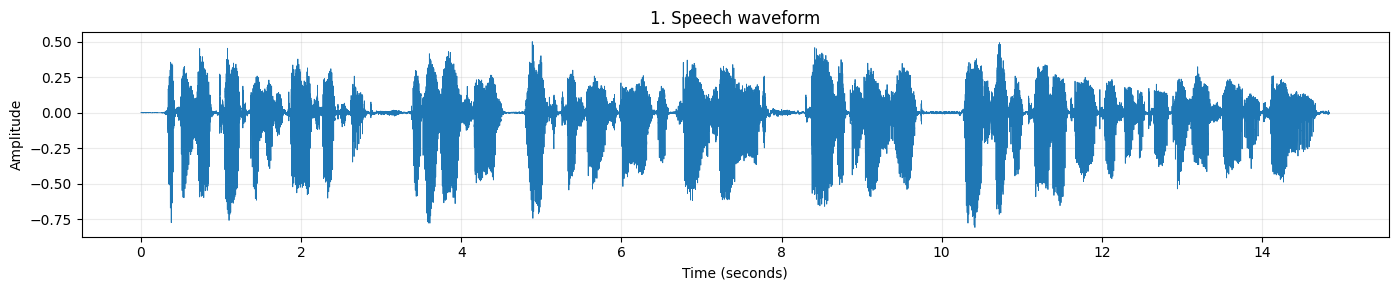

In [ ]:
plt.figure(figsize=(14, 3))
plt.plot(time, audio, linewidth=0.6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("1. Speech waveform")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation**
- The graph points correctly at 3 clear pauses.
  1. between 2 - 4 s
  2. between 7 - 9 s
  3. between 9 - 11 s

- The thick blobs represent syllables, each burst of energy can roughly be 1 syllable or word.
- Speech starts at ~0.3 s; the start is a quiet lead-in.
- Peaks reach about ±0.75, so nothing hits ±1 → no **clipping** (distortion when a recording is too loud for its range).
- Amplitude depends on microphone distance and recording gain, so it is neither loudness nor pitch.

## 3.2 Spectrogram

- **Spectrogram** = how energy is distributed over **time** (x) and **frequency** (y); brightness = relative power.
- A 25 ms window is used. Shorter windows show timing more sharply but blur frequency; longer windows do the opposite. 25 ms is a common middle ground for speech.

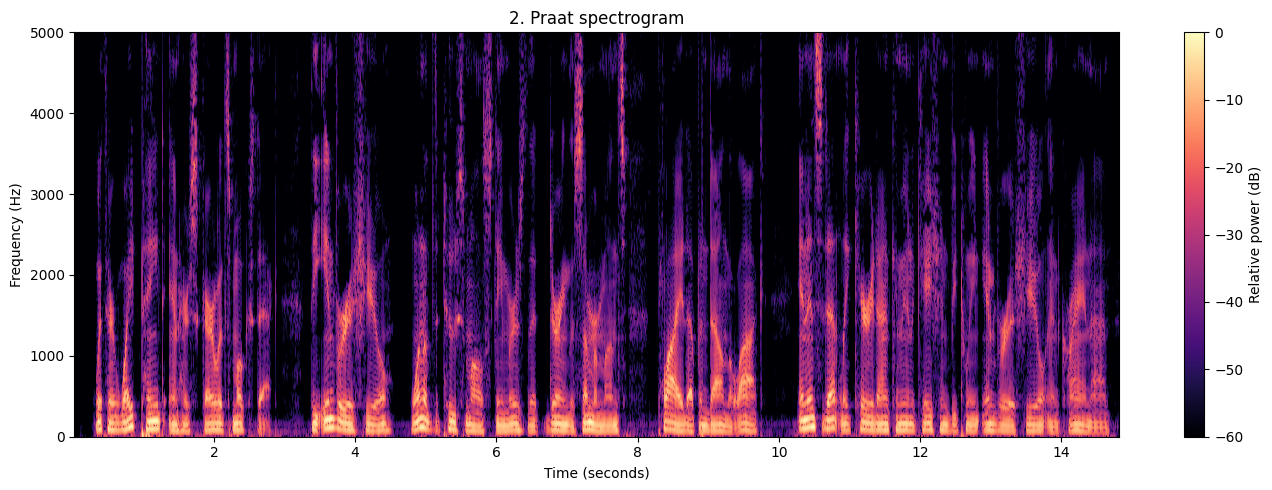

In [ ]:
spectrogram = sound.to_spectrogram(
    window_length=0.025,       # 25 ms analysis window
    maximum_frequency=5000,
    time_step=0.005,            # 5 ms between frames
    frequency_step=20,
)

spec_values = spectrogram.values

# Convert the power values to a relative dB scale
spec_db = 10 * np.log10(np.maximum(spec_values, 1e-12))
spec_db = spec_db - np.max(spec_db)

spec_times = (
    spectrogram.x1
    + np.arange(spec_values.shape[1]) * spectrogram.dx
)

spec_freqs = (
    spectrogram.y1
    + np.arange(spec_values.shape[0]) * spectrogram.dy
)

plt.figure(figsize=(14, 5))
plt.pcolormesh(
    spec_times,
    spec_freqs,
    spec_db,
    shading="auto",
    cmap="magma",
    vmin=-60,
    vmax=0,
)
plt.ylim(0, 5000)
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("2. Praat spectrogram")
plt.colorbar(label="Relative power (dB)")
plt.tight_layout()
plt.show()

**Interpretation**
- Yellow band = 0 dB (strongest point) and black band = -60 dB (weaker points)
- Bright strips are stacked near the bottom below ~500 Hz
- Tightly packed strips at the bottom resemble low pitch thus matching a low male voice.
- The black columns match with the three pauses observed in waveform.
- The strips are **harmonics** — energy at F0, 2×F0, 3×F0 … — so the gap between two strips equals the pitch (~80 Hz here).
- Broad bright bands that bend between 500 and 2,500 Hz are **formants** (vocal-tract resonances); their movement is the vowels changing.
- Tall thin streaks reaching 4,000–5,000 Hz (near 1.8, 7.2 and 10.6 s) are **fricatives** such as /s/ — noise with no harmonics.
- For a typical female voice (~200 Hz), the strips would be ~200 Hz apart: about 2 strips below 500 Hz instead of ~6, and formant bands ~15–20% higher.

# 4. Praat analysis through Parselmouth

- Time step for all Praat measurements: **10 ms**.
- Pitch range: **fitted to this speaker** (53–129 Hz) after the mistake recorded below.

## 4.1 Pitch (F0)

- **Fundamental frequency (F0)** = the rate at which the vocal folds vibrate, in Hz. Closely related to perceived **pitch**.
- **Pitch tracking** = estimating F0 frame by frame. Praat's `to_pitch_cc` uses cross-correlation. Only **voiced** frames get a value; unvoiced frames are `NaN`.

### Attempt 1 — initial assumption

- The pitch tracker was first run with the range **75–500 Hz**, on the assumption that a default range suits any adult voice.
- Result of attempt 1:

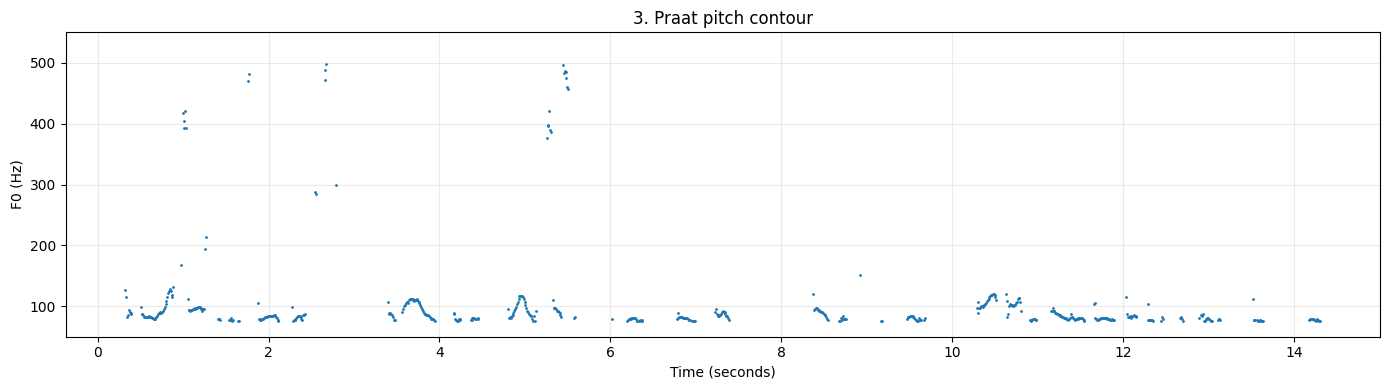

- Each dot = one 10 ms frame where Praat found voicing.
- Gaps observed could mean unvoiced sounds, pauses or tracking failures.
- Smooth curves symbolize intonation - rises and falls within a phrase.
- The dots observed above ~200 Hz are tracking errors.
- The main contour lies between 75 - 120 Hz, with small rises observed resembling the stressed words.
- Many dots sit flat near 75 Hz, due to 75 Hz floor cutting the voice off.
- The median is reported instead of the mean, as the mean is pulled by extreme values (which are the tracking errors observed above), whereas median is not.
- Praat advices to use a range of 75 - 300 Hz for male voices.
- Printed in attempt 1: 554 valid frames, median 83.4 Hz, 10th–90th percentile 76.9–114.3 Hz; mean 104 Hz.

### Mistake realised

- The 75 Hz floor was above part of this speaker's voice, so Praat stopped reporting his lowest stretches instead of measuring them.
- Evidence from attempt 1:
  - 24.5% of Praat F0 values sat within 5% of the 75 Hz floor.
  - Praat found only 37.4% voiced frames; openSMILE found 70.1%.
  - openSMILE's 20th percentile was ≈ 68 Hz — below Praat's floor.
  - Spikes at 380–500 Hz pulled the mean (104 Hz) far above the median (83 Hz).
- The same 75 Hz value was also used in intensity, harmonicity and the voice report, so the mistake spread to those too.

### Correction made

- The range was fitted to the speaker with a **two-pass method** (De Looze & Hirst, 2008): a wide first search (50–700 Hz), then floor = 0.75 × 25th percentile and ceiling = 1.5 × 75th percentile.
- `F0_FLOOR` and `F0_CEILING` are used in the pitch, intensity, harmonicity, PointProcess, voice report and reliability cells.

In [ ]:
# Two-pass pitch range: wide first search, then a range fitted to THIS speaker
first_pass = sound.to_pitch_cc(time_step=0.01, pitch_floor=50, pitch_ceiling=700)
f0_first = first_pass.selected_array["frequency"]
f0_first = f0_first[f0_first > 0]          # voiced frames only

q25, q75 = np.percentile(f0_first, [25, 75])
F0_FLOOR = int(round(0.75 * q25))
F0_CEILING = int(round(1.5 * q75))
print(f"Quartiles: {q25:.1f} / {q75:.1f} Hz -> F0_FLOOR = {F0_FLOOR} Hz, F0_CEILING = {F0_CEILING} Hz")

Quartiles: 70.8 / 85.8 Hz -> F0_FLOOR = 53 Hz, F0_CEILING = 129 Hz


**Two-pass result**
- Quartiles observed: 70.8 Hz (25th) and 85.8 Hz (75th).
- Fitted range: **F0_FLOOR = 53 Hz, F0_CEILING = 129 Hz** — much narrower and lower than 75–500 Hz.
- The 25th percentile itself (70.8 Hz) is below the old 75 Hz floor, which confirms the floor was cutting the voice off.

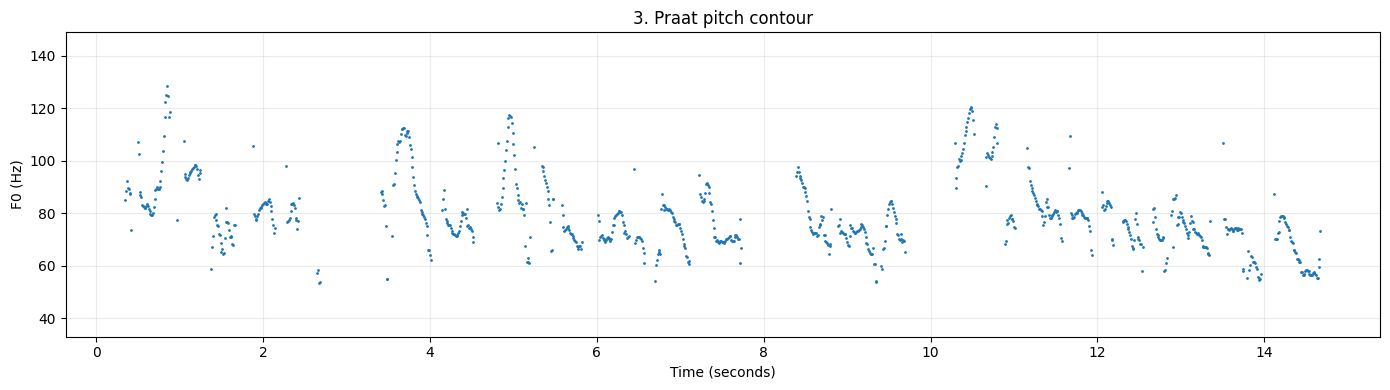

Valid pitch frames: 910
Median F0: 76.9 Hz
10th–90th percentile: [64.8 97.8] Hz


In [ ]:
pitch = sound.to_pitch_cc(
    time_step=0.01,
    pitch_floor=F0_FLOOR,
    pitch_ceiling=F0_CEILING,
)

pitch_times = (
    pitch.x1
    + np.arange(pitch.get_number_of_frames()) * pitch.dx
)

pitch_values = np.array([
    pitch.get_value_at_time(t)
    for t in pitch_times
])

# Treat non-positive or undefined values as missing
pitch_values[pitch_values <= 0] = np.nan

plt.figure(figsize=(14, 4))
plt.plot(pitch_times, pitch_values, ".", markersize=2)
plt.xlabel("Time (seconds)")
plt.ylabel("F0 (Hz)")
plt.title("3. Praat pitch contour")
plt.ylim(F0_FLOOR-20, F0_CEILING+20)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

valid_pitch = pitch_values[np.isfinite(pitch_values)]

if len(valid_pitch):
    print("Valid pitch frames:", len(valid_pitch))
    print("Median F0:", round(np.median(valid_pitch), 1), "Hz")
    print(
        "10th–90th percentile:",
        np.round(np.percentile(valid_pitch, [10, 90]), 1),
        "Hz",
    )
else:
    print("No valid pitch estimates. Check the pitch settings.")

**Change noticed**

| | Attempt 1 (75–500 Hz) | After correction (53–129 Hz) |
|---|---|---|
| Valid pitch frames | 554 | **910** |
| Median F0 | 83.4 Hz | **76.9 Hz** |
| 10th–90th percentile | 76.9–114.3 Hz | **64.8–97.8 Hz** |
| Spikes at 380–500 Hz | Present | **Gone** (above the new ceiling) |

**New interpretation**
- The main contour now lies between ~55 - 120 Hz; the lowest stretches (~55–60 Hz near 2.7, 9.3 and 13.8–14.6 s) were invisible in attempt 1.
- Rises observed near 0.9, 3.7, 4.9 and 10.5 s (up to ~120–128 Hz) resemble the stressed words.
- Within phrases pitch drifts downward, e.g. ~90 Hz at 11.2 s falling to ~55 Hz at 14.6 s → **declination** (pitch falls across a phrase, then resets).
- No dots sit pressed against the floor any more, and no tracking spikes are left.
- The typical pitch of this speaker is ~77 Hz, lower than first measured (83 Hz). The attempt-1 median was biased upward because the lowest frames were cut off.

## 4.2 Intensity

- **Intensity** = the signal's energy over short windows, in dB, by Praat's conventions.
- Praat treats sample values as pressure in pascals, so for this uncalibrated recording the dB values are **relative**, not true sound pressure levels.
- Correction applied: `minimum_pitch` changed from 75 to `F0_FLOOR` (53 Hz). Praat's intensity window is ~3.2 ÷ minimum pitch, so it became longer (~60 ms instead of ~43 ms) to fit this low voice.

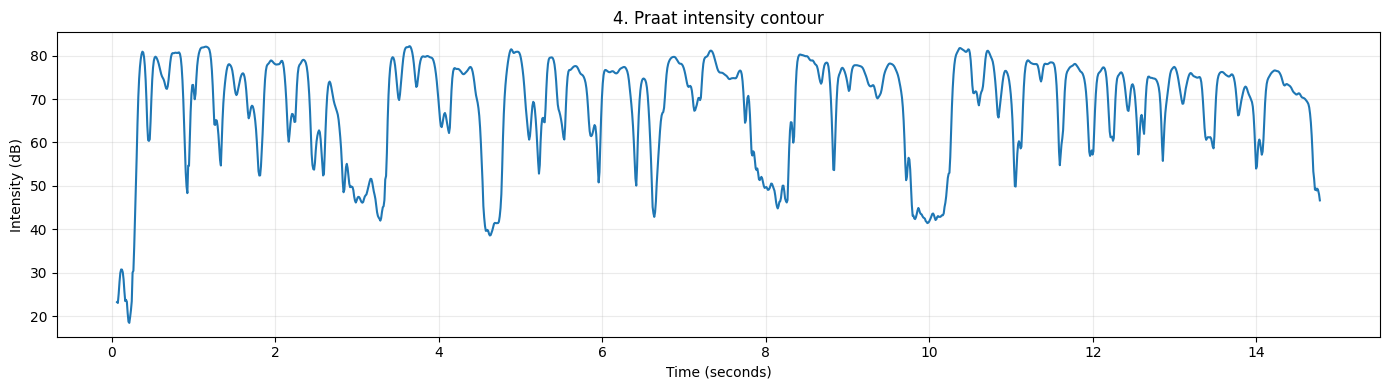

In [ ]:
intensity = sound.to_intensity(
    minimum_pitch=F0_FLOOR,
    time_step=0.01,
)

intensity_times = (
    intensity.x1
    + np.arange(intensity.get_number_of_frames()) * intensity.dx
)

intensity_values = np.array([
    intensity.get_value(t)  # FIX: Intensity objects have get_value(time); get_value_at_time does not exist
    for t in intensity_times
])

plt.figure(figsize=(14, 4))
plt.plot(intensity_times, intensity_values)
plt.xlabel("Time (seconds)")
plt.ylabel("Intensity (dB)")
plt.title("4. Praat intensity contour")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation**
- Speech sits at about 75–82 dB; the three pauses drop to about 40–50 dB; the quiet lead-in at the start is near 20 dB.
- Gap between speech and pauses ≈ 30–40 dB (**dynamic range**) → speech stands well above the background.
- Valleys also appear inside words (quiet consonants such as /t/ or /s/), so a low value does not prove silence. Energy alone is not a perfect voice activity detector.
- Change after the correction was small: mean 67.7 → 68.2 dB, median 72.7 → 72.9 dB. The curve now starts at ~0.06 s instead of ~0.045 s because of the longer window.

## 4.3 Formants

- **Formants** = resonances of the vocal tract (throat, mouth, nose), numbered from the lowest up.

| Formant | Mainly controlled by | Low value | High value | Example (average adult male) |
|---|---|---|---|---|
| **F1** | Jaw opening / tongue height | Closed mouth (/i/ "beet", /u/ "boot") | Open mouth (/a/ "father") | /i/ ~270 Hz, /a/ ~730 Hz |
| **F2** | Tongue front–back position | Tongue back (/u/) | Tongue front (/i/) | /u/ ~870 Hz, /i/ ~2,290 Hz |
| **F3** | Lip rounding, /r/, vocal-tract length | /r/ pulls it down to ~1,700 Hz | Spread lips, most vowels | ~2,400–2,600 Hz |

- F1 and F2 together identify the vowel (example values: Peterson & Barney, 1952; female values are ~15–20% higher).

### Attempt 1 — initial assumption

- Formants were measured with the Burg method, up to 5 formants below **5500 Hz**, in **every 10 ms frame** of the clip (next cell, kept as it was).

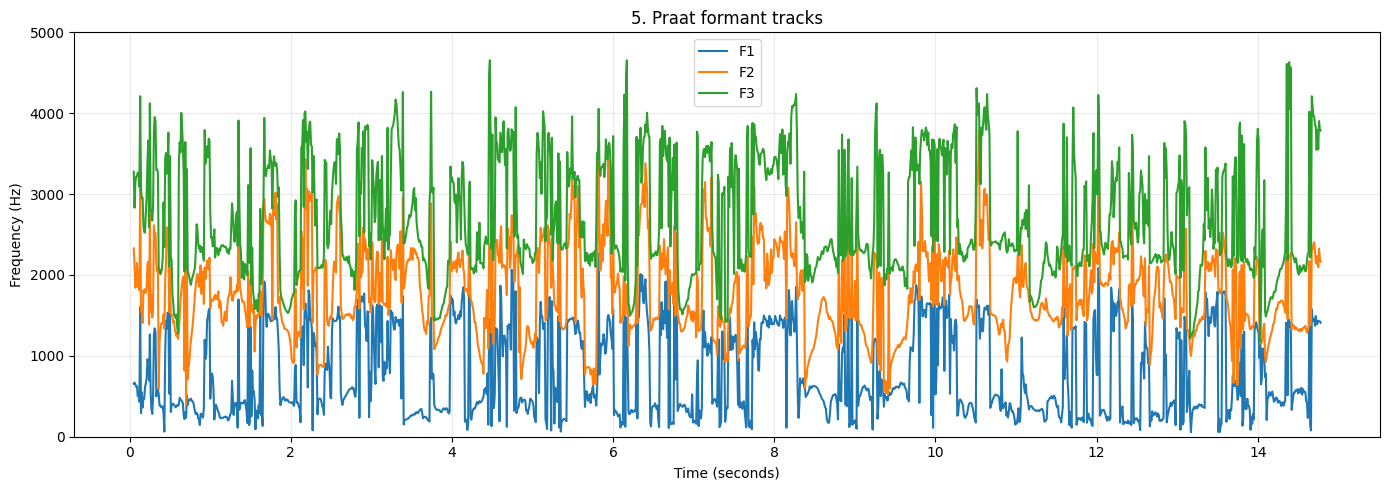

In [ ]:
formants = sound.to_formant_burg(
    time_step=0.01,
    max_number_of_formants=5,
    maximum_formant=5500,
    window_length=0.025,
    pre_emphasis_from=50,
)

formant_times = np.arange(0.05, duration - 0.05, 0.01)

f1, f2, f3 = [], [], []

for t in formant_times:
    f1.append(formants.get_value_at_time(1, t))
    f2.append(formants.get_value_at_time(2, t))
    f3.append(formants.get_value_at_time(3, t))

f1 = np.array(f1, dtype=float)
f2 = np.array(f2, dtype=float)
f3 = np.array(f3, dtype=float)

plt.figure(figsize=(14, 5))
plt.plot(formant_times, f1, label="F1")
plt.plot(formant_times, f2, label="F2")
plt.plot(formant_times, f3, label="F3")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("5. Praat formant tracks")
plt.ylim(0, 5000)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

- Observed in attempt 1: very jumpy tracks; F1 often leapt from ~300 Hz to ~1,500 Hz between neighbouring frames.

### Mistake realised

- A male F1 rarely exceeds ~900 Hz, so many of these values were wrong.
- Two settings caused it:
  1. **Every frame was measured**, including pauses and consonants where no formants exist; Burg's method still returns numbers there.
  2. **5500 Hz** is Praat's ceiling for typical female voices. For a male voice Praat recommends **5000 Hz**; a too-high ceiling makes the tracker squeeze in an extra resonance and mislabel the real ones.

### Correction made

- Ceiling changed to **5000 Hz**.
- Only frames that are voiced (Praat pitch present) **and** within 25 dB of the loudest frame are kept — roughly the vowels.

Frames kept: 910 of 1474


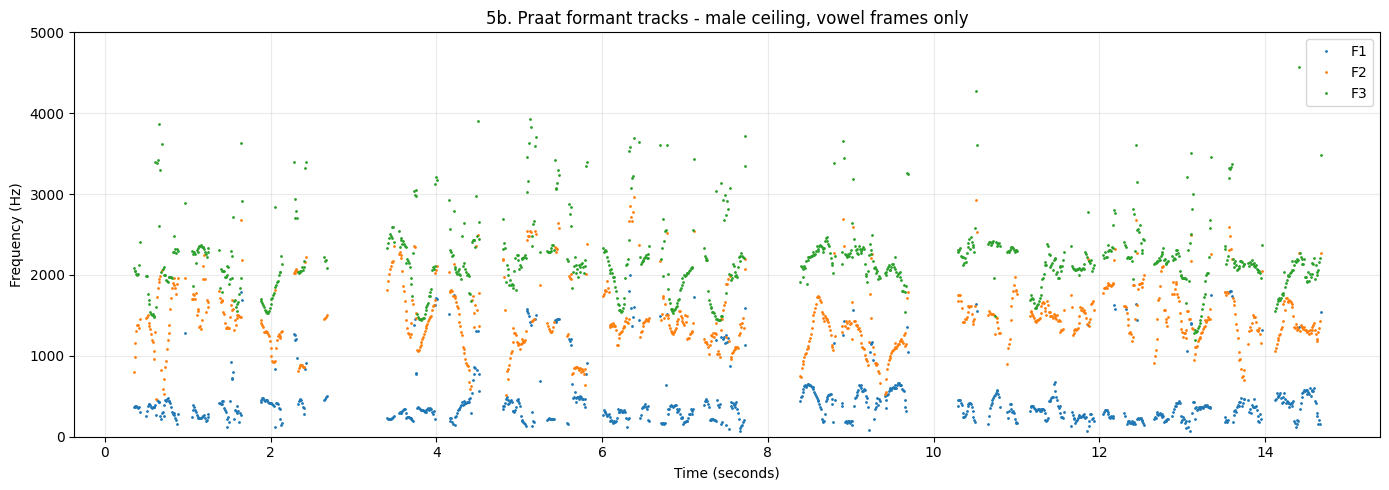

In [ ]:
# Formants, corrected: male ceiling + only voiced, loud frames (vowels)
formants_fixed = sound.to_formant_burg(
    time_step=0.01,
    max_number_of_formants=5,
    maximum_formant=5000,      # male voice: 5000 Hz (5500 suits female voices)
    window_length=0.025,
    pre_emphasis_from=50,
)

f1_fixed = np.array([formants_fixed.get_value_at_time(1, t) for t in formant_times])
f2_fixed = np.array([formants_fixed.get_value_at_time(2, t) for t in formant_times])
f3_fixed = np.array([formants_fixed.get_value_at_time(3, t) for t in formant_times])

# Keep a frame only if Praat finds voicing AND it is within 25 dB of the loudest frame
voiced = np.array([np.isfinite(pitch.get_value_at_time(t)) for t in formant_times])
loud = np.array([intensity.get_value(t) for t in formant_times])
keep = voiced & (loud > np.nanmax(loud) - 25)
for f in (f1_fixed, f2_fixed, f3_fixed):
    f[~keep] = np.nan

print("Frames kept:", keep.sum(), "of", len(keep))

plt.figure(figsize=(14, 5))
plt.plot(formant_times, f1_fixed, ".", markersize=2, label="F1")
plt.plot(formant_times, f2_fixed, ".", markersize=2, label="F2")
plt.plot(formant_times, f3_fixed, ".", markersize=2, label="F3")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("5b. Praat formant tracks - male ceiling, vowel frames only")
plt.ylim(0, 5000)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Change noticed**
- Frames kept: **910 of 1474** (the rest were pauses, consonants and quiet frames).
- The tracks separated into three clear bands instead of the earlier tangle.

**New interpretation**
- **F1** mostly lies between ~200 - 600 Hz → plausible for a male voice; the 1,500 Hz jumps are gone.
- **F2** mostly lies between ~1,000 - 2,500 Hz, moving up and down as vowels change front/back.
- **F3** mostly lies around ~2,000 - 2,500 Hz, with scattered dots at 3,000–4,500 Hz that are still tracking errors.
- The 25 dB threshold is a rule of thumb, not a vowel detector — it can keep a loud consonant or drop a quiet vowel.

## 4.4 Harmonicity (HNR)

- **Harmonics** = the sine waves at F0, 2×F0, 3×F0 … that a voiced (periodic) sound is made of. For this speaker (~77 Hz): ~77, 154, 231 Hz …
- Source–filter model: the vocal folds make the harmonics (**source**); the vocal tract boosts those near the formants (**filter**). Unvoiced sounds (/s/, /f/) have no harmonics — they are noise.
- **Harmonics-to-noise ratio (HNR)** = harmonic energy compared with noise energy, in dB. High = clean, periodic voice; low = breathy, hoarse, creaky or noisy.
- Why harmonics matter: their spacing gives pitch, their presence gives voicing, their strength vs noise gives HNR, and their relative strength gives voice quality and spectral tilt.
- Praat writes **−200 dB** where no periodicity is found; this is a code for "undefined", so it is converted to `NaN`.

### Attempt 1 — initial assumption

- Harmonicity was run with `minimum_pitch = 75` Hz, the same default as the pitch tracker.

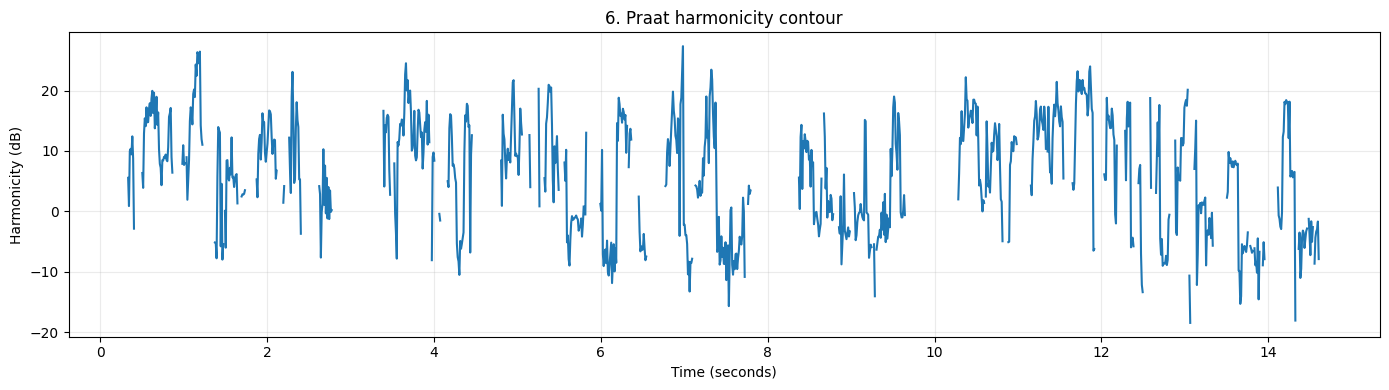

- Observed in attempt 1: clear vowels at 10–25 dB, but many stretches at −5 to −15 dB, often at phrase ends (6.0–7.8 s, 13–14.6 s). Mean 6.0 dB, median 6.9 dB over 902 frames; 39.1% of frames undefined.
- The low stretches were first read as possible **creaky voice** (a low, irregular vibration at phrase ends).

### Mistake realised

- The low stretches lined up with the places where pitch went **below 75 Hz**. Praat's analysis window is set from `minimum_pitch`; with 75 Hz it was too short to hold enough cycles of a ~55–70 Hz voice, so those frames looked noisy.
- So the low HNR was at least partly caused by the setting, not by the voice.

### Correction made

- `minimum_pitch` changed to `F0_FLOOR` (53 Hz).

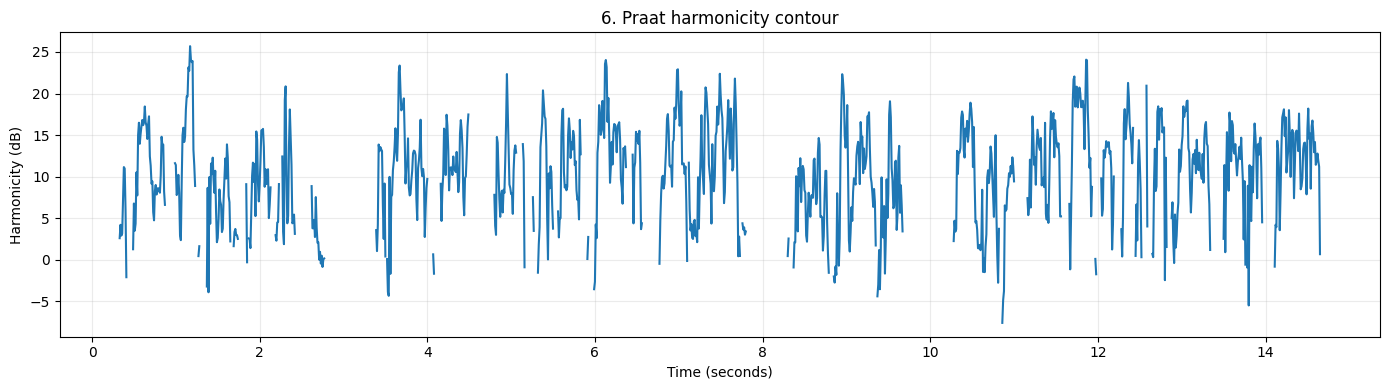

In [ ]:
harmonicity = sound.to_harmonicity_cc(
    time_step=0.01,
    minimum_pitch=F0_FLOOR,
)

harm_times = (
    harmonicity.x1
    + np.arange(harmonicity.get_number_of_frames())
    * harmonicity.dx
)

harm_values = np.array([
    harmonicity.get_value(t)  # FIX: Harmonicity objects have get_value(time); get_value_at_time does not exist
    for t in harm_times
])

# FIX: Praat returns -200 dB where no periodicity is found (silence / unvoiced).
# That is a code for 'undefined', not a measurement, so treat it as missing.
harm_values[harm_values <= -199] = np.nan

plt.figure(figsize=(14, 4))
plt.plot(harm_times, harm_values)
plt.xlabel("Time (seconds)")
plt.ylabel("Harmonicity (dB)")
plt.title("6. Praat harmonicity contour")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Change noticed**

| | Attempt 1 (min pitch 75 Hz) | After correction (53 Hz) |
|---|---|---|
| Defined frames | 902 | **984** |
| Mean HNR | 6.0 dB | **10.3 dB** |
| Median HNR | 6.9 dB | **10.9 dB** |
| Undefined (−200 dB) frames | 39.1% | **33.6%** |

**New interpretation**
- HNR now mostly lies between ~5 - 25 dB; it rarely drops below 0 dB (lowest ~ −7 dB near 10.9 s).
- The −5 to −15 dB stretches at phrase ends are gone → the creaky-voice reading was mostly a measurement artifact of the 75 Hz setting.
- Some creak may still exist at phrase ends (pitch ~55 Hz there), but HNR no longer gives strong evidence for it.
- The voice is clearer than attempt 1 suggested: a typical voiced frame has ~11 dB more harmonic than noise energy.

## 4.5 Jitter and shimmer

- **Jitter** = variation in the **durations** of successive vocal-fold cycles.
- **Shimmer** = variation in the **amplitudes** of successive cycles.
- Both are most interpretable in a **stable, sustained vowel**, not an arbitrary stretch of a sentence.
- The window **0.50–1.00 s** (next cell) is used in both runs.

In [ ]:
segment_start = 0.50
segment_end = 1.00

assert 0 <= segment_start < segment_end <= duration

segment = audio[
    int(segment_start * sample_rate):
    int(segment_end * sample_rate)
]

display(Audio(segment, rate=sample_rate))

- Praat's **Voice report** needs three objects together: the `Sound`, a `Pitch` and a `PointProcess` (the detected glottal pulses).
- Both the PointProcess and the report now use the fitted range `F0_FLOOR`–`F0_CEILING`.

In [ ]:
point_process = parselmouth.praat.call(
    sound,
    "To PointProcess (periodic, cc)",
    F0_FLOOR,
    F0_CEILING,
)

voice_report = parselmouth.praat.call(
    [sound, pitch, point_process],  # FIX: Praat's Voice report needs Sound + Pitch + PointProcess together
    "Voice report",
    segment_start,
    segment_end,
    F0_FLOOR,
    F0_CEILING,
    1.3,
    1.6,
    0.03,
    0.45,
)

print(voice_report)

   From 0.500000 to 1.000000 seconds (duration: 0.500000 seconds)
Pitch:
   Median pitch: 88.049 Hz
   Mean pitch: 93.587 Hz
   Standard deviation: 15.294 Hz
   Minimum pitch: 77.545 Hz
   Maximum pitch: 128.470 Hz
Pulses:
   Number of pulses: 37
   Number of periods: 36
   Mean period: 10.580331E-3 seconds
   Standard deviation of period: 1.724764E-3 seconds
Voicing:
   Fraction of locally unvoiced frames: 22.000%   (11 / 50)
   Number of voice breaks: 0
   Degree of voice breaks: 0   (0 seconds / 0 seconds)
Jitter:
   Jitter (local): 2.993%
   Jitter (local, absolute): 316.680E-6 seconds
   Jitter (rap): 0.748%
   Jitter (ppq5): 1.360%
   Jitter (ddp): 2.244%
Shimmer:
   Shimmer (local): 9.686%
   Shimmer (local, dB): 0.861 dB
   Shimmer (apq3): 4.129%
   Shimmer (apq5): 5.691%
   Shimmer (apq11): 9.936%
   Shimmer (dda): 12.388%
Harmonicity of the voiced parts only:
   Mean autocorrelation: 0.902407
   Mean noise-to-harmonics ratio: 0.119862
   Mean harmonics-to-noise ratio: 11.400 

### Attempt 1 — initial assumption

- The report was run on 0.50–1.00 s with the range 75–500 Hz.
- Observed: median 89.1 Hz, mean 104.1 Hz, **max 417.0 Hz**, 18% unvoiced frames, 1 voice break (24% of the window), jitter (local) 2.97%, shimmer (local) 9.45% (0.86 dB), HNR 12.2 dB.

### Mistake realised

- The 417 Hz maximum was the tracking spike near 1.0 s falling inside the window.
- The window is not a steady vowel: it holds a pitch rise, an unvoiced part and a voice break.

### Correction made

- Range changed to the fitted 53–129 Hz. The window was kept the same (0.50–1.00 s) so that the effect of the range alone could be seen.

**Change noticed**

| | Attempt 1 | After range correction |
|---|---|---|
| Max pitch | 417.0 Hz | **128.5 Hz** |
| Mean / median pitch | 104.1 / 89.1 Hz | **93.6 / 88.0 Hz** |
| Voice breaks | 1 | **0** |
| Unvoiced frames | 18% | 22% |
| Jitter (local) | 2.97% | 2.99% |
| Shimmer (local) | 9.45% | 9.69% |
| HNR | 12.2 dB | 11.4 dB |

**New interpretation**
- The spike and the voice break disappeared, so the pitch part of the report is now trustworthy.
- Jitter and shimmer **did not change**. Their high values (2.99%, 9.69%) are therefore not caused by the spike; they come from the content of the window — a pitch rise from ~78 to ~128 Hz in running speech.
- These jitter and shimmer values are not interpreted as voice quality. They are acoustic measurements, not diagnoses.
- **Still open:** choosing a steady 0.3–0.5 s vowel would give meaningful jitter and shimmer.

# 5. openSMILE feature extraction

## 5.1 eGeMAPSv02 functionals

- The same `audio` array and `sample_rate` used for Praat go into `process_signal`.
- `FeatureLevel.Functionals` gives one summary row for the whole signal.
- openSMILE was not affected by the Praat pitch-range mistake; its numbers are identical in both runs.

In [ ]:
smile_functionals = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)

functional_features = smile_functionals.process_signal(
    audio,
    sample_rate,
)

print("Functionals shape:", functional_features.shape)
display(functional_features.T.rename(columns={0: "value"}))

Functionals shape: (1, 88)


start,0 days
end,0 days 00:00:14.840000
F0semitoneFrom27.5Hz_sma3nz_amean,18.818953
F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.369501
F0semitoneFrom27.5Hz_sma3nz_percentile20.0,15.619290
F0semitoneFrom27.5Hz_sma3nz_percentile50.0,17.534452
F0semitoneFrom27.5Hz_sma3nz_percentile80.0,20.031361
...,...
MeanVoicedSegmentLengthSec,0.237619
StddevVoicedSegmentLengthSec,0.180895
MeanUnvoicedSegmentLength,0.094878


**Observations**
- The output is 1 row × 88 functionals, as documented for `eGeMAPSv02`.
- F0 functionals observed: mean 18.82 st (≈ 81 Hz), percentiles 20/50/80 = 15.62 / 17.53 / 20.03 st (≈ 68 / 76 / 87 Hz).
- `equivalentSoundLevel_dBp` = −19.0 — a relative level, not a calibrated dB SPL.

In [ ]:
print(functional_features.columns.tolist())

['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope', 'loudness_sma3_amean', 'loudness_sma3_stddevNorm', 'loudness_sma3_percentile20.0', 'loudness_sma3_percentile50.0', 'loudness_sma3_percentile80.0', 'loudness_sma3_pctlrange0-2', 'loudness_sma3_meanRisingSlope', 'loudness_sma3_stddevRisingSlope', 'loudness_sma3_meanFallingSlope', 'loudness_sma3_stddevFallingSlope', 'spectralFlux_sma3_amean', 'spectralFlux_sma3_stddevNorm', 'mfcc1_sma3_amean', 'mfcc1_sma3_stddevNorm', 'mfcc2_sma3_amean', 'mfcc2_sma3_stddevNorm', 'mfcc3_sma3_amean', 'mfcc3_sma3_stddevNorm', 'mfcc4_sma3_amean', 'mfcc4_sma3_std

### 5.2 Reading eGeMAPS column names

- Each column name is a recipe, e.g. `F0semitoneFrom27.5Hz_sma3nz_percentile20.0` = pitch in semitones above 27.5 Hz, smoothed over 3 frames, voiced frames only, 20th percentile.

| Name part | Meaning |
|---|---|
| `F0semitoneFrom27.5Hz` | Pitch: F0 in semitones, 0 = 27.5 Hz; st = 12·log₂(Hz ÷ 27.5); 12 st = one octave |
| `loudness` / `Loudness` | Perceived-loudness estimate (no physical unit) |
| `HNRdBACF` | Harmonics-to-noise ratio, dB, autocorrelation-based |
| `jitterLocal`, `shimmerLocaldB` | Voice-quality measurements |
| `alphaRatio`, `hammarbergIndex`, `slope…` | Spectral balance |
| `F1frequency`, `F1bandwidth` … | Formant-related |
| `mfcc1–4` | Mel-frequency cepstral coefficients (compact spectral-shape descriptors) |
| `_sma3` | Smoothed with a 3-frame moving average |
| `nz` | Functional computed over **non-zero** (voiced) frames only |
| `V` / `UV` | Voiced / unvoiced regions only |
| `_amean` | Arithmetic mean |
| `_stddevNorm` | Standard deviation ÷ mean (coefficient of variation) |
| `_percentile20.0` …, `_pctlrange0-2` | Percentiles; range between 20th and 80th percentile |
| `_meanRisingSlope` … | Mean/std of rising or falling slopes |

- Definitions: openSMILE Python usage guide and Eyben et al. (2016).

## 5.3 Low-level descriptors (LLDs)

- LLDs keep one row per frame, so the variation over time is preserved.
- The output is 1,476 frames × 25 descriptors.

In [ ]:
smile_lld = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.LowLevelDescriptors,
)

lld_features = smile_lld.process_signal(
    audio,
    sample_rate,
)

print("LLD shape:", lld_features.shape)
display(lld_features.head())
print("\nAvailable columns:")
print(lld_features.columns.tolist())

LLD shape: (1476, 25)


,,Loudness_sma3,alphaRatio_sma3,hammarbergIndex_sma3,slope0-500_sma3,slope500-1500_sma3,spectralFlux_sma3,mfcc1_sma3,mfcc2_sma3,mfcc3_sma3,mfcc4_sma3,...,logRelF0-H1-A3_sma3nz,F1frequency_sma3nz,F1bandwidth_sma3nz,F1amplitudeLogRelF0_sma3nz,F2frequency_sma3nz,F2bandwidth_sma3nz,F2amplitudeLogRelF0_sma3nz,F3frequency_sma3nz,F3bandwidth_sma3nz,F3amplitudeLogRelF0_sma3nz
start,end,,,,,,,,,,,,,,,,,,,,,
0 days 00:00:00,0 days 00:00:00.020000,0.023739,-17.353800,23.095200,-0.066021,-0.011827,0.002367,12.343011,11.115002,16.549116,4.406221,...,0.0,490.646881,1257.963745,-201.0,1830.185059,779.538513,-201.0,2863.271484,1520.674194,-201.0
0 days 00:00:00.010022676,0 days 00:00:00.030022676,0.023277,-14.979369,20.450640,-0.061742,-0.008390,0.003282,11.465210,10.169682,17.874298,8.459788,...,0.0,409.572601,1288.606323,-201.0,1594.463257,825.415283,-201.0,2546.202393,1074.281250,-201.0
0 days 00:00:00.020045351,0 days 00:00:00.040045351,0.022591,-11.840341,17.750246,-0.041444,-0.008622,0.004067,10.617377,8.473409,15.168961,8.928672,...,0.0,386.110748,1200.484375,-201.0,1423.003540,904.446472,-201.0,2215.825439,766.910156,-201.0
0 days 00:00:00.030068027,0 days 00:00:00.050068027,0.023181,-12.371638,18.558945,-0.025850,-0.010986,0.002491,12.738927,10.723553,15.661475,9.137326,...,0.0,375.972626,1224.836792,-201.0,1396.723511,944.035828,-201.0,2180.807617,753.730408,-201.0
0 days 00:00:00.040090703,0 days 00:00:00.060090703,0.024650,-12.317111,18.565741,0.001692,-0.016659,0.002354,14.553086,10.360336,11.544545,2.905158,...,0.0,424.027863,1063.179321,-201.0,1417.350220,943.611633,-201.0,2226.778320,719.830566,-201.0



Available columns:
['Loudness_sma3', 'alphaRatio_sma3', 'hammarbergIndex_sma3', 'slope0-500_sma3', 'slope500-1500_sma3', 'spectralFlux_sma3', 'mfcc1_sma3', 'mfcc2_sma3', 'mfcc3_sma3', 'mfcc4_sma3', 'F0semitoneFrom27.5Hz_sma3nz', 'jitterLocal_sma3nz', 'shimmerLocaldB_sma3nz', 'HNRdBACF_sma3nz', 'logRelF0-H1-H2_sma3nz', 'logRelF0-H1-A3_sma3nz', 'F1frequency_sma3nz', 'F1bandwidth_sma3nz', 'F1amplitudeLogRelF0_sma3nz', 'F2frequency_sma3nz', 'F2bandwidth_sma3nz', 'F2amplitudeLogRelF0_sma3nz', 'F3frequency_sma3nz', 'F3bandwidth_sma3nz', 'F3amplitudeLogRelF0_sma3nz']


- openSMILE indexes each LLD row by its `start` and `end` time; the helper below converts them to frame mid-points in seconds.
- Frame step observed: **0.010022676 s**, not exactly 0.01 s. At 22,050 Hz, 10 ms = 220.5 samples, so openSMILE rounds to 221 samples (10.02 ms).

In [ ]:
def opensmile_frame_times(features):
    """Return frame midpoint times in seconds."""
    idx = features.index

    if isinstance(idx, pd.MultiIndex):
        starts = idx.get_level_values("start")
        ends = idx.get_level_values("end")
        return (
            (starts + (ends - starts) / 2).total_seconds()
        )

    # Fallback for a simple index
    if isinstance(idx, pd.TimedeltaIndex):
        return idx.total_seconds()

    raise ValueError(
        "Unexpected openSMILE index format. Inspect features.index."
    )


lld_times = opensmile_frame_times(lld_features)

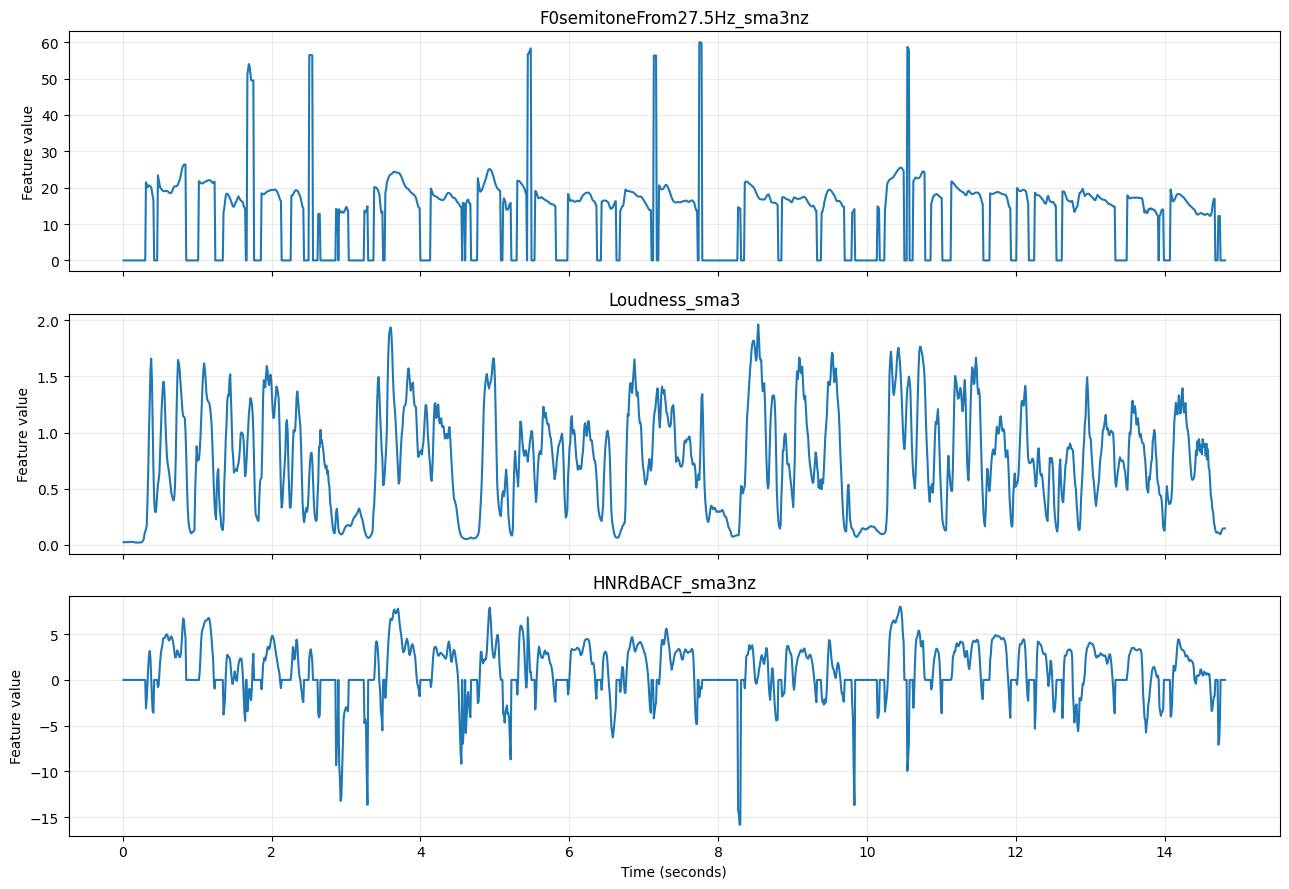

In [ ]:
wanted_terms = ["F0semitone", "Loudness", "HNR"]
selected_columns = []

for term in wanted_terms:
    matches = [
        col for col in lld_features.columns
        if term.lower() in col.lower()
    ]
    if matches:
        selected_columns.append(matches[0])

if not selected_columns:
    print("No matching columns. Inspect the available feature names.")
else:
    fig, axes = plt.subplots(
        len(selected_columns),
        1,
        figsize=(13, 3 * len(selected_columns)),
        sharex=True,
    )

    axes = np.atleast_1d(axes)

    for ax, column in zip(axes, selected_columns):
        ax.plot(lld_times, lld_features[column].to_numpy())
        ax.set_title(column)
        ax.set_ylabel("Feature value")
        ax.grid(alpha=0.25)

    axes[-1].set_xlabel("Time (seconds)")
    plt.tight_layout()
    plt.show()

**Interpretation**
- **F0semitoneFrom27.5Hz_sma3nz:** the main contour lies between ~13 - 25 st (≈ 58–117 Hz). Drops to 0 = unvoiced frames, not a pitch of zero.
- Spikes observed to 50–60 st (≈ 500–900 Hz) near 1.7, 2.5, 5.5, 7.2, 7.7 and 10.5 s are tracking errors (cleaned in Section 6.2).
- **Loudness_sma3:** speech peaks reach 1.5–2.0; pauses fall near 0.1 → same pause pattern as the waveform. Arbitrary units, no dB.
- **HNRdBACF_sma3nz:** mostly −5 to +8 dB. Here 0 can mean unvoiced *or* a real 0 dB, so voicing has to be checked before averaging.
- In openSMILE LLDs, columns ending `nz` write **0** for unvoiced frames, while Praat writes `NaN` — both are "not measured" codes.

## 5.4 LLDs vs functionals — sizes

In [ ]:
print("Number of LLD frames:", len(lld_features))
print("Number of LLD descriptors:", len(lld_features.columns))
print("Number of functional rows:", len(functional_features))
print("Number of functional features:", len(functional_features.columns))

print("\nFirst 10 LLD rows:")
display(lld_features.iloc[:10, :min(10, len(lld_features.columns))])

print("\nFirst 10 functionals:")
display(functional_features.iloc[:, :10].T)

Number of LLD frames: 1476
Number of LLD descriptors: 25
Number of functional rows: 1
Number of functional features: 88

First 10 LLD rows:


,,Loudness_sma3,alphaRatio_sma3,hammarbergIndex_sma3,slope0-500_sma3,slope500-1500_sma3,spectralFlux_sma3,mfcc1_sma3,mfcc2_sma3,mfcc3_sma3,mfcc4_sma3
start,end,,,,,,,,,,
0 days 00:00:00,0 days 00:00:00.020000,0.023739,-17.353800,23.095200,-0.066021,-0.011827,0.002367,12.343011,11.115002,16.549116,4.406221
0 days 00:00:00.010022676,0 days 00:00:00.030022676,0.023277,-14.979369,20.450640,-0.061742,-0.008390,0.003282,11.465210,10.169682,17.874298,8.459788
0 days 00:00:00.020045351,0 days 00:00:00.040045351,0.022591,-11.840341,17.750246,-0.041444,-0.008622,0.004067,10.617377,8.473409,15.168961,8.928672
0 days 00:00:00.030068027,0 days 00:00:00.050068027,0.023181,-12.371638,18.558945,-0.025850,-0.010986,0.002491,12.738927,10.723553,15.661475,9.137326
0 days 00:00:00.040090703,0 days 00:00:00.060090703,0.024650,-12.317111,18.565741,0.001692,-0.016659,0.002354,14.553086,10.360336,11.544545,2.905158
0 days 00:00:00.050113379,0 days 00:00:00.070113379,0.025202,-12.886673,18.746338,0.004222,-0.019414,0.002444,16.653418,11.531029,8.772358,-1.078840
0 days 00:00:00.060136054,0 days 00:00:00.080136054,0.024783,-13.354367,18.924320,0.002072,-0.018064,0.002565,17.170105,11.503552,6.944764,-3.668111
0 days 00:00:00.070158730,0 days 00:00:00.090158730,0.024987,-15.017163,21.441803,-0.017989,-0.021904,0.003192,18.254519,11.684060,6.231531,-6.176580
0 days 00:00:00.080181406,0 days 00:00:00.100181406,0.025505,-17.889215,24.955963,-0.033718,-0.022567,0.003724,19.115675,13.640408,8.965788,-2.938571



First 10 functionals:


start,0 days
end,0 days 00:00:14.840000
F0semitoneFrom27.5Hz_sma3nz_amean,18.818953
F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.369501
F0semitoneFrom27.5Hz_sma3nz_percentile20.0,15.619290
F0semitoneFrom27.5Hz_sma3nz_percentile50.0,17.534452
F0semitoneFrom27.5Hz_sma3nz_percentile80.0,20.031361
F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,4.412070
F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,440.848328
F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,650.153687
F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,134.836914


**Observations**
- LLDs: 1,476 frames × 25 descriptors (a time series). Functionals: 1 row × 88 values (a summary of the whole clip).
- The pitch slope functionals observed are very large: mean rising slope 440.8 st/s, mean falling slope 134.8 st/s. These are inflated by the 50–60 st spikes, which jump 30–40 st in one frame → slope functionals are very sensitive to tracking errors.
- Functionals compress temporal information, so the order of events is lost.

## 5.5 Praat vs openSMILE

Why values differ between the tools:
- **Algorithms:** Praat pitch uses cross-correlation; openSMILE eGeMAPS uses subharmonic summation.
- **Units:** Praat F0 in Hz vs openSMILE semitones above 27.5 Hz; Praat intensity in dB vs openSMILE loudness with no physical unit.
- **Settings:** window length, pitch range, smoothing (`sma3`), voicing thresholds.
- **Voicing decisions:** which frames each tool counts as voice.
- So timing and shape are compared first; raw values only on a common scale (Section 6.3).

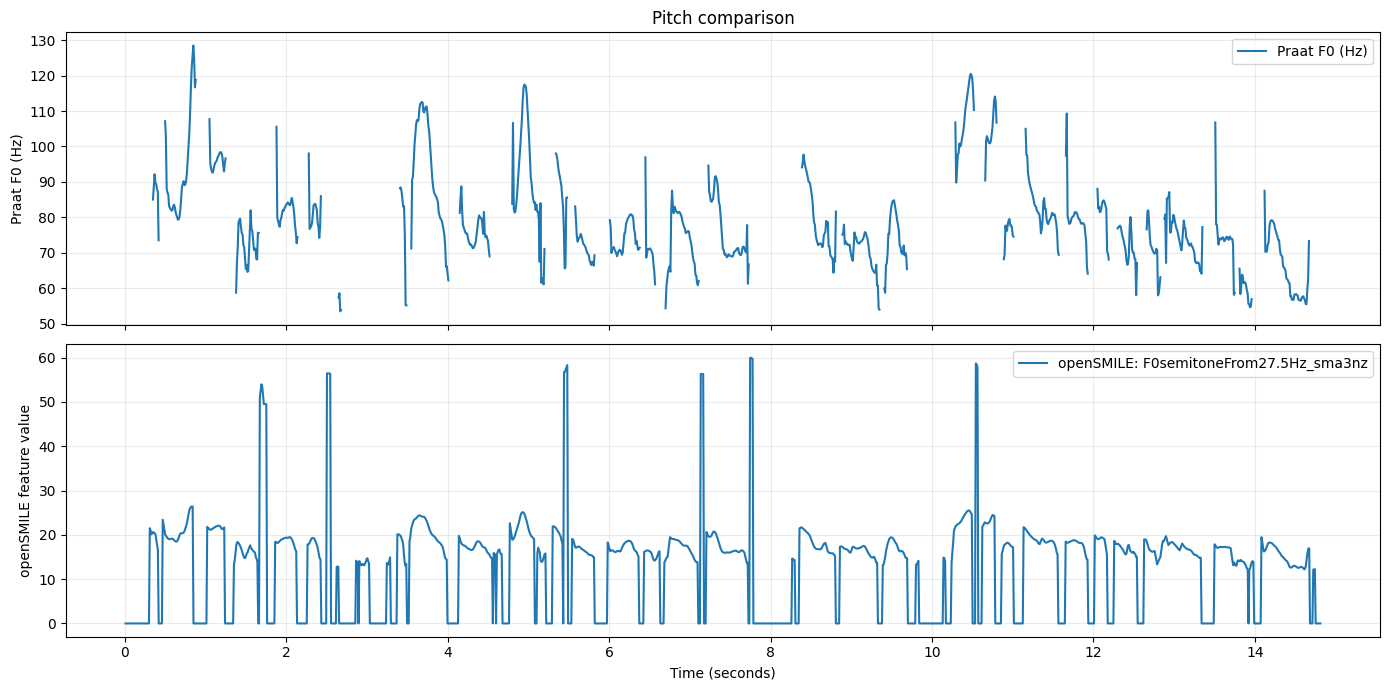

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(pitch_times, pitch_values, label="Praat F0 (Hz)")
axes[0].set_ylabel("Praat F0 (Hz)")
axes[0].set_title("Pitch comparison")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Find an openSMILE pitch-related LLD column
pitch_columns = [
    col for col in lld_features.columns
    if "f0semitone" in col.lower()
]

if pitch_columns:
    col = pitch_columns[0]
    axes[1].plot(
        lld_times,
        lld_features[col].to_numpy(),
        label=f"openSMILE: {col}",
    )
    axes[1].set_ylabel("openSMILE feature value")
    axes[1].legend()
else:
    axes[1].text(
        0.02, 0.8,
        "No matching F0semitone LLD column found. "
        "Inspect lld_features.columns.",
        transform=axes[1].transAxes,
    )

axes[1].set_xlabel("Time (seconds)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Inspect potentially comparable feature names
feature_names = functional_features.columns.tolist()

for term in ["F0", "Loudness", "HNR", "jitter", "shimmer"]:
    print(f"\n{term}:")
    print([name for name in feature_names if term.lower() in name.lower()])


F0:
['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope', 'logRelF0-H1-H2_sma3nz_amean', 'logRelF0-H1-H2_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_stddevNorm', 'F1amplitudeLogRelF0_sma3nz_amean', 'F1amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm']

Loudness:
['loudness_sma3_amean', 'loudness_sma3_stddevNorm', 'loudness_sma3_percentile20.0', 'loudness_sma3_percentile50.0', 'loudness_sma3_percentile80.0', 'loudness_sma3_

- The openSMILE pitch panel is in semitones and Praat in Hz, so the heights cannot be compared directly.
- The next cell lists the comparable names at both levels (functionals and LLDs).

In [ ]:
# Inspect available eGeMAPS functionals and LLDs
for term in ["F0", "Loudness", "HNR", "jitter", "shimmer"]:
    print(f"\n--- {term} ---")

    print("Functionals:", [
        c for c in functional_features.columns
        if term.lower() in c.lower()
    ])

    print("LLDs:", [
        c for c in lld_features.columns
        if term.lower() in c.lower()
    ])


--- F0 ---
Functionals: ['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope', 'logRelF0-H1-H2_sma3nz_amean', 'logRelF0-H1-H2_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_stddevNorm', 'F1amplitudeLogRelF0_sma3nz_amean', 'F1amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm']
LLDs: ['F0semitoneFrom27.5Hz_sma3nz', 'logRelF0-H1-H2_sma3nz', 'logRelF0-H1-A3_sma3nz', 'F1amplitudeLogRelF0_sma3nz', 'F2amplitudeLogRelF0_sma3nz', 'F3amp

### 5.6 Praat time-series table

- Praat pitch, intensity and harmonicity on one 10 ms time grid; the −200 dB harmonicity code converted to `NaN`.
- First rows observed: all `NaN` until 0.05 s. With `minimum_pitch` = 53 Hz the intensity window is ~60 ms, so the first full window is centred later than in attempt 1 (where intensity started at 0.05 s). Missing values at the edges are normal for windowed analysis.

In [ ]:
analysis_times = np.arange(0.01, duration, 0.01)

praat_comparison = pd.DataFrame({
    "time_seconds": analysis_times,
    "praat_pitch_hz": [
        pitch.get_value_at_time(t) for t in analysis_times
    ],
    "praat_intensity_db": [
        intensity.get_value(t) for t in analysis_times  # FIX: get_value, not get_value_at_time
    ],
    "praat_harmonicity_db": [
        harmonicity.get_value(t) for t in analysis_times  # FIX: get_value, not get_value_at_time
    ],
})

praat_comparison = praat_comparison.replace(
    [np.inf, -np.inf], np.nan
)

# FIX: Praat's -200 dB harmonicity code means 'undefined' -> missing
praat_comparison.loc[
    praat_comparison["praat_harmonicity_db"] <= -199, "praat_harmonicity_db"
] = np.nan

display(praat_comparison.head())

,time_seconds,praat_pitch_hz,praat_intensity_db,praat_harmonicity_db
0,0.01,NaN,NaN,NaN
1,0.02,NaN,NaN,NaN
2,0.03,NaN,NaN,NaN
3,0.04,NaN,NaN,NaN
4,0.05,NaN,NaN,NaN


### 5.7 Pitch contours side by side (Hz vs semitones)

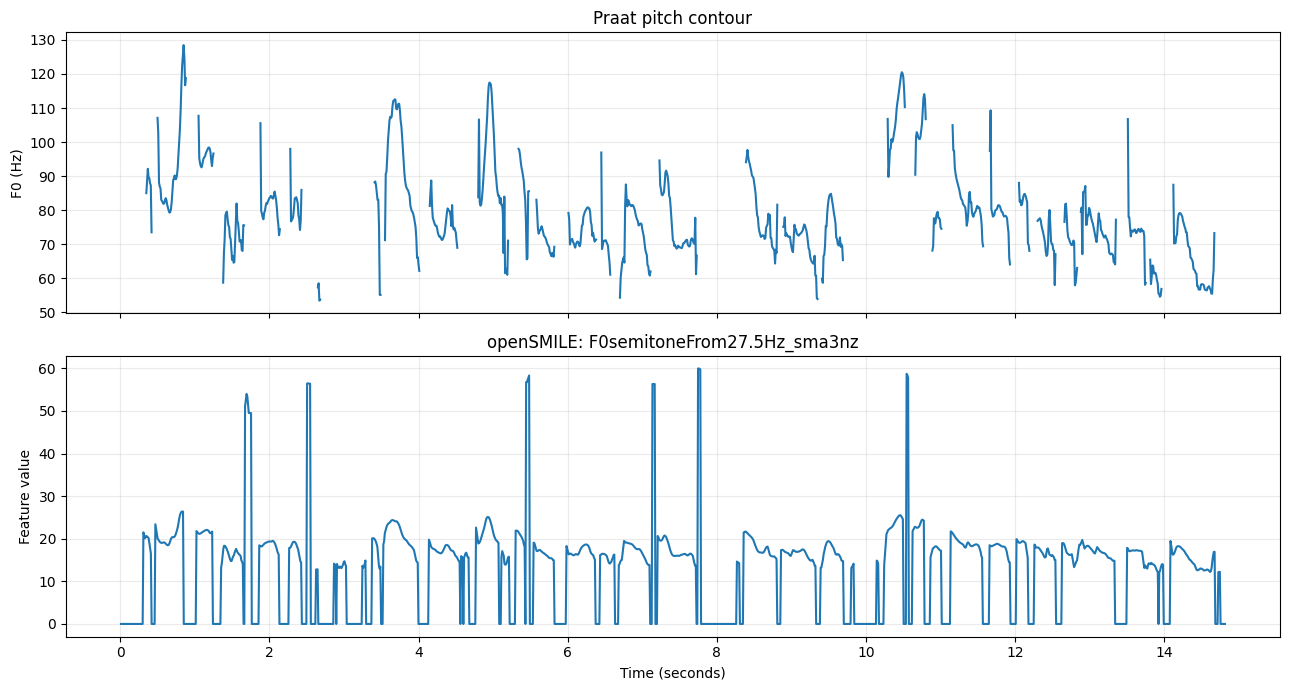

In [ ]:
pitch_columns = [
    c for c in lld_features.columns
    if "f0semitone" in c.lower()
]

if pitch_columns:
    smile_pitch_column = pitch_columns[0]

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    axes[0].plot(
        praat_comparison["time_seconds"],
        praat_comparison["praat_pitch_hz"],
    )
    axes[0].set_ylabel("F0 (Hz)")
    axes[0].set_title("Praat pitch contour")
    axes[0].grid(alpha=0.25)

    axes[1].plot(
        lld_times,
        lld_features[smile_pitch_column].to_numpy(),
    )
    axes[1].set_ylabel("Feature value")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_title(f"openSMILE: {smile_pitch_column}")
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

else:
    print("No F0semitone LLD found. Check the feature names.")

**Interpretation**
- Both panels show the same voiced periods, gaps and broad rises and falls.
- Heights differ because of units (Hz vs st), so similar shapes do not mean equal numbers.
- The openSMILE line drops to 0 in unvoiced frames and shows its own 50–60 st spikes.

### 5.8 Intensity vs loudness, and HNR names

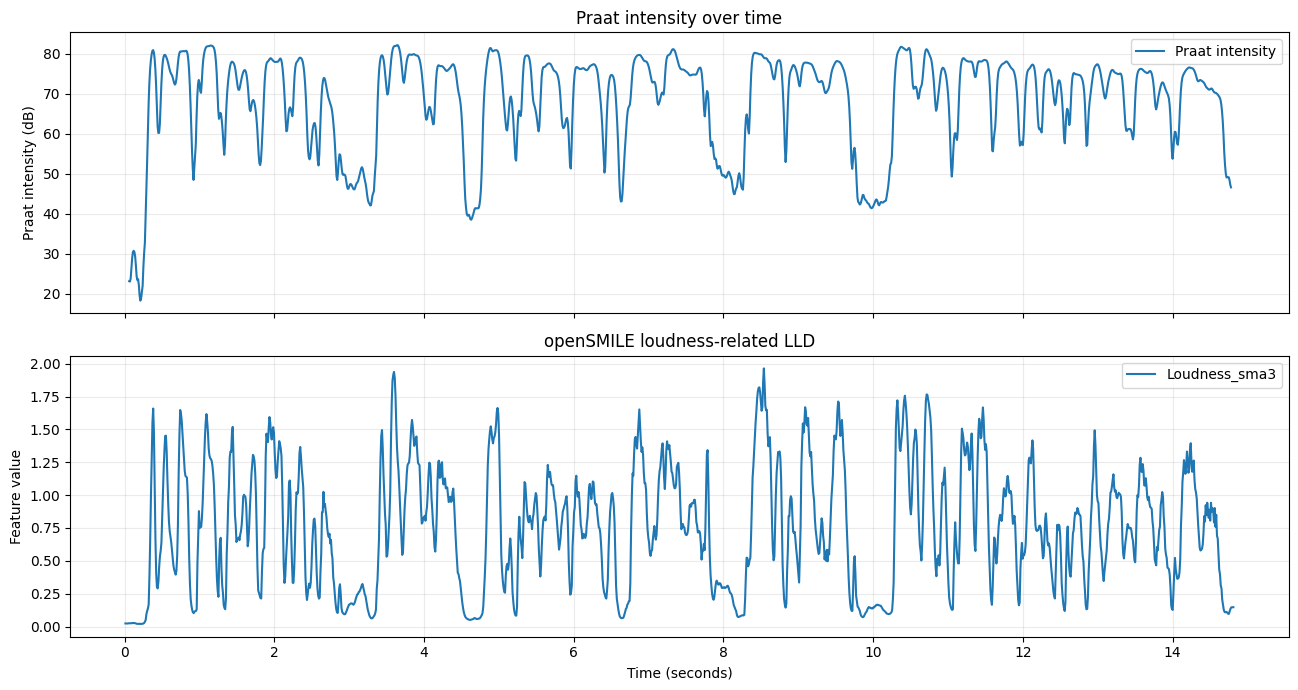

HNR-related LLD candidates: ['HNRdBACF_sma3nz']


In [ ]:
# Find candidate openSMILE LLD columns
loudness_columns = [
    c for c in lld_features.columns
    if "loudness" in c.lower()
]

hnr_columns = [
    c for c in lld_features.columns
    if "hnr" in c.lower()
]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(
    praat_comparison["time_seconds"],
    praat_comparison["praat_intensity_db"],
    label="Praat intensity",
)
axes[0].set_ylabel("Praat intensity (dB)")
axes[0].set_title("Praat intensity over time")
axes[0].grid(alpha=0.25)
axes[0].legend()

if loudness_columns:
    col = loudness_columns[0]
    axes[1].plot(lld_times, lld_features[col].to_numpy(), label=col)
    axes[1].set_title("openSMILE loudness-related LLD")
else:
    axes[1].text(
        0.05, 0.5,
        "No loudness-related LLD found in this configuration.",
        transform=axes[1].transAxes,
    )

axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Feature value")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

print("HNR-related LLD candidates:", hnr_columns)

**Interpretation**
- Praat intensity (dB) and openSMILE loudness (no physical unit) rise and fall together at the same times — same pauses, same syllable peaks.
- They are related but not the same measurement, so only their temporal patterns are compared.
- HNR LLD available in this version: `HNRdBACF_sma3nz`.

# 6. Interpreting the feature table (Goal 1)

## 6.1 Feature dictionary — 8 eGeMAPSv02 columns

- The next cell checks that these exact column names exist in the output.

| Column | Meaning | Unit or scale | LLD or functional | Interpretation caveat |
|---|---|---|---|---|
| `F0semitoneFrom27.5Hz_sma3nz_amean` | Mean pitch over voiced frames | Semitones above 27.5 Hz; +12 st = one octave | Functional (mean of an LLD) | Voiced frames only; octave errors pull the mean; speaker-dependent |
| `F0semitoneFrom27.5Hz_sma3nz_stddevNorm` | Pitch variability | Ratio (std ÷ mean) | Functional | Says how much pitch varies, not how; unstable with few voiced frames |
| `loudness_sma3_amean` | Mean perceived-loudness estimate | Arbitrary units — **not dB** | Functional | Depends on mic distance and gain; compare within one recording only |
| `HNRdBACF_sma3nz_amean` | Mean harmonics-to-noise ratio | dB | Functional | Voiced frames only; lowered by noise and compression |
| `jitterLocal_sma3nz_amean` | Mean period-to-period variation in cycle length | Ratio (0.015 ≈ 1.5%) | Functional | Meaningful mainly in sustained voicing; inflated by tracking errors |
| `shimmerLocaldB_sma3nz_amean` | Mean cycle-to-cycle amplitude variation | dB | Functional | Same as jitter; also sensitive to noise |
| `alphaRatioV_sma3nz_amean` | Energy 50–1000 Hz vs 1–5 kHz, voiced regions | dB | Functional | Affected by microphone and channel |
| `VoicedSegmentsPerSec` | Continuous voiced stretches per second | Count per second | Functional (temporal) | **Not** syllable or speaking rate |

- Sources: openSMILE Python usage guide; Eyben et al. (2016). The jitter scale was checked against Praat: openSMILE ≈ 0.035 where Praat reported ≈ 3%.

In [ ]:
# (new) Check the dictionary columns exist in YOUR output and show this recording's values
feature_dictionary = pd.DataFrame([
    ("F0semitoneFrom27.5Hz_sma3nz_amean",      "semitones re 27.5 Hz"),
    ("F0semitoneFrom27.5Hz_sma3nz_stddevNorm", "ratio (std/mean)"),
    ("loudness_sma3_amean",                    "arbitrary loudness units"),
    ("HNRdBACF_sma3nz_amean",                  "dB"),
    ("jitterLocal_sma3nz_amean",               "ratio (x100 = %)"),
    ("shimmerLocaldB_sma3nz_amean",            "dB"),
    ("alphaRatioV_sma3nz_amean",               "dB"),
    ("VoicedSegmentsPerSec",                   "count per second"),
], columns=["column", "unit_or_scale"])

missing = [c for c in feature_dictionary["column"] if c not in functional_features.columns]
if missing:
    print("WARNING - not found in your installed eGeMAPS version:", missing)
    print("Pick replacements from functional_features.columns (printed in Section 5).")

feature_dictionary["value_libri1"] = [
    functional_features[c].iloc[0] if c in functional_features.columns else np.nan
    for c in feature_dictionary["column"]
]
display(feature_dictionary)

,column,unit_or_scale,value_libri1
0,F0semitoneFrom27.5Hz_sma3nz_amean,semitones re 27.5 Hz,18.818953
1,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,ratio (std/mean),0.369501
2,loudness_sma3_amean,arbitrary loudness units,0.757988
3,HNRdBACF_sma3nz_amean,dB,1.378399
4,jitterLocal_sma3nz_amean,ratio (x100 = %),0.034733
5,shimmerLocaldB_sma3nz_amean,dB,1.275896
6,alphaRatioV_sma3nz_amean,dB,-16.117224
7,VoicedSegmentsPerSec,count per second,2.849390


**Interpretation of the values**

| Feature | Value | In plain terms | Reading |
|---|---|---|---|
| F0 mean | 18.82 st | ≈ 81 Hz | Low male voice (typical male ~85–155 Hz) |
| F0 stddevNorm | 0.37 | std = 37% of mean | Inflated by the spikes; the 20–80% range (4.4 st) is the honest spread |
| Loudness mean | 0.76 | Arbitrary units | Only useful against other segments of the same recording |
| HNR mean | 1.38 dB | Harmonic ≈ noise energy | Much lower than Praat's 10.3 dB after correction — different algorithm and voicing decision |
| Jitter mean | 0.0347 | 3.5% | High for running speech with a pitch rise; not a voice-quality verdict |
| Shimmer mean | 1.28 dB | — | Same reason as jitter |
| Alpha ratio | −16.1 dB | Energy above 1 kHz is ~16 dB weaker than below | Normal for speech |
| Voiced segments / s | 2.85 | ~2.85 voiced stretches per second | Average stretch 0.24 s; not syllables per second |

- So the table describes a low, fairly monotone voice (20–80% range only 4.4 st).
- The voice-quality numbers here are inflated by measurement issues, so they are not read as properties of the voice.

## 6.2 LLD vs functional — example from this recording

- Blue dots (next plot) = the F0 LLD, one per voiced frame; red dashed line = the single functional `amean`.
- `nz` means the mean uses **voiced frames only**, so it is compared with the mean of the non-zero LLD values.

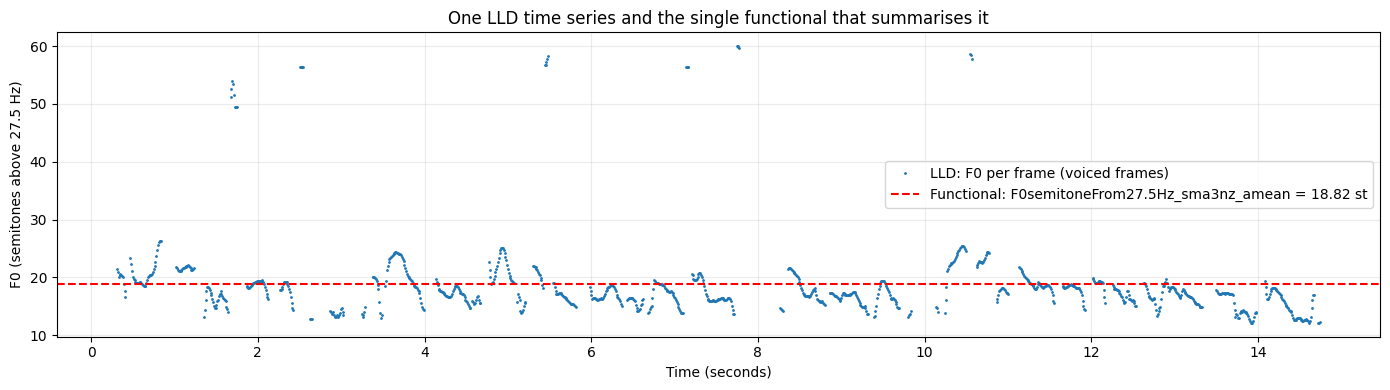

LLD frames: 1476 | voiced frames: 1035 (70.1% of frames)
Mean of voiced LLD frames: 18.819
openSMILE functional amean: 18.819 (small differences come from openSMILE's internal processing order)
Mean of the REVERSED sequence: 18.819 -> identical: the mean does not keep temporal order


In [ ]:
# (new) One LLD vs its functional
F0_LLD = "F0semitoneFrom27.5Hz_sma3nz"
F0_MEAN = F0_LLD + "_amean"

if F0_LLD not in lld_features.columns or F0_MEAN not in functional_features.columns:
    raise KeyError(f"{F0_LLD} / {F0_MEAN} not in this eGeMAPS output - check the column lists in Section 5.")

f0_lld = lld_features[F0_LLD].to_numpy(dtype=float)
f0_voiced_mask = f0_lld > 0                       # 0 = unvoiced frame in openSMILE
f0_lld_plot = np.where(f0_voiced_mask, f0_lld, np.nan)
f0_functional_mean = functional_features[F0_MEAN].iloc[0]

plt.figure(figsize=(14, 4))
plt.plot(lld_times, f0_lld_plot, ".", markersize=2, label="LLD: F0 per frame (voiced frames)")
plt.axhline(f0_functional_mean, color="red", linestyle="--",
            label=f"Functional: {F0_MEAN} = {f0_functional_mean:.2f} st")
plt.xlabel("Time (seconds)")
plt.ylabel("F0 (semitones above 27.5 Hz)")
plt.title("One LLD time series and the single functional that summarises it")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("LLD frames:", len(f0_lld), "| voiced frames:", f0_voiced_mask.sum(),
      f"({100 * f0_voiced_mask.mean():.1f}% of frames)")
print("Mean of voiced LLD frames:", round(np.nanmean(f0_lld_plot), 3))
print("openSMILE functional amean:", round(f0_functional_mean, 3),
      "(small differences come from openSMILE's internal processing order)")
print("Mean of the REVERSED sequence:", round(np.nanmean(f0_lld_plot[::-1]), 3),
      "-> identical: the mean does not keep temporal order")

**Observations**
- 1,035 of 1,476 frames voiced (70.1%); one red line stands in for 1,035 dots.
- Mean of voiced LLD frames = 18.819 = functional `amean` 18.819 → `amean` is exactly the average of the non-zero frames.
- Mean of the reversed sequence = 18.819 → identical. The mean cannot tell a rising contour from a falling one; temporal order (what intonation is made of) is lost.

### Attempt 1 — initial assumption

- The openSMILE F0 functionals were reported as they were: mean 18.82 st, stddevNorm 0.37, rising slope 440.8 st/s.

### Mistake realised

- The LLD contains spikes to 50–60 st (≈ 500–900 Hz) — tracking errors far from the ~17 st contour. They pull the mean up and inflate the spread and slope functionals.

### Correction made

- Every F0 frame more than **12 st (one octave)** from the speaker's median was removed and the summaries were recomputed (next cell).
- The eGeMAPS configuration itself was not changed, so the official functionals stay comparable with other studies.

In [ ]:
# Remove F0 values more than one octave (12 st) from the speaker's median
f0_st = lld_features["F0semitoneFrom27.5Hz_sma3nz"].to_numpy(dtype=float)
f0_st[f0_st == 0] = np.nan                       # 0 = unvoiced, not a pitch
spikes = np.abs(f0_st - np.nanmedian(f0_st)) > 12
f0_st_clean = np.where(spikes, np.nan, f0_st)

print("Spike frames removed:", int(spikes.sum()))
print("Mean before / after:", round(np.nanmean(f0_st), 2), "/", round(np.nanmean(f0_st_clean), 2), "st")
print("Median after:", round(np.nanmedian(f0_st_clean), 2), "st | 20-80% range:",
      np.round(np.nanpercentile(f0_st_clean, [20, 80]), 2), "st")

Spike frames removed: 30
Mean before / after: 18.82 / 17.72 st
Median after: 17.38 st | 20-80% range: [15.57 19.58] st


**Change noticed**

| | openSMILE functional (attempt 1) | After cleaning |
|---|---|---|
| Spike frames | 30 included | **30 removed** |
| Mean | 18.82 st (≈ 81 Hz) | **17.72 st (≈ 76.5 Hz)** |
| Median | 17.53 st (≈ 75.7 Hz) | **17.38 st (≈ 75.0 Hz)** |
| 20–80% range | 15.62–20.03 st | **15.57–19.58 st (≈ 68–85 Hz)** |

**New interpretation**
- The cleaned mean (≈ 76.5 Hz) now agrees with the corrected Praat median (76.9 Hz); the official functional mean (81 Hz) was biased upward by 30 spike frames.
- The percentiles hardly moved → percentiles are robust to a few errors, while the mean is not.
- The 12 st rule is simple, not perfect: a very expressive speaker could genuinely move more than an octave.

## 6.3 Praat vs openSMILE pitch on the same scale

- Praat Hz converted with st = 12·log₂(F0 ÷ 27.5), so both tools sit on openSMILE's scale and differences reflect algorithms and settings, not units.

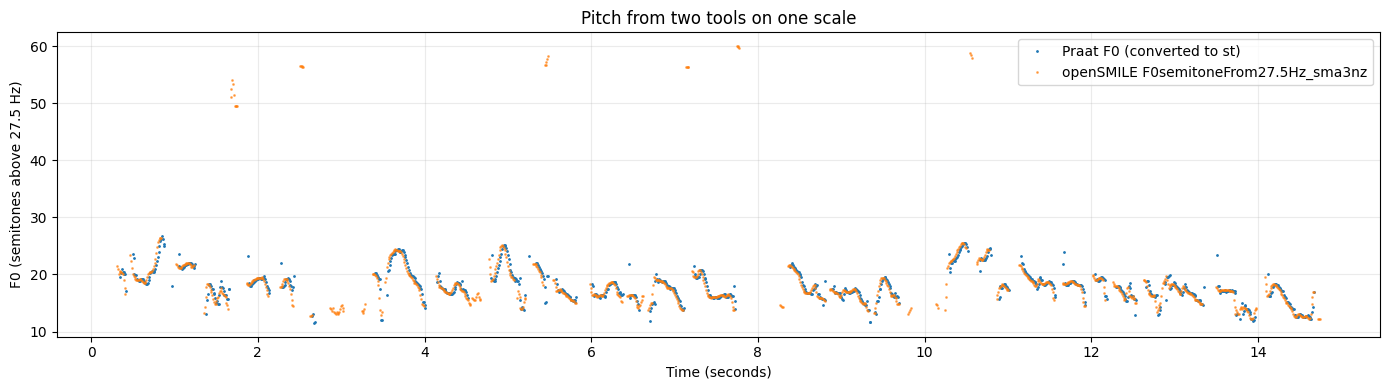

Median F0, Praat    : 17.81 st
Median F0, openSMILE: 17.53 st


In [ ]:
# (new) Convert Praat Hz -> semitones re 27.5 Hz and overlay with the openSMILE LLD
praat_f0_st = 12 * np.log2(pitch_values / 27.5)      # NaN stays NaN (unvoiced)

plt.figure(figsize=(14, 4))
plt.plot(pitch_times, praat_f0_st, ".", markersize=2, label="Praat F0 (converted to st)")
plt.plot(lld_times, f0_lld_plot, ".", markersize=2, alpha=0.6, label="openSMILE F0semitoneFrom27.5Hz_sma3nz")
plt.xlabel("Time (seconds)")
plt.ylabel("F0 (semitones above 27.5 Hz)")
plt.title("Pitch from two tools on one scale")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Median F0, Praat    :", round(np.nanmedian(praat_f0_st), 2), "st")
print("Median F0, openSMILE:", round(np.nanmedian(f0_lld_plot), 2), "st")

### Attempt 1 — initial assumption

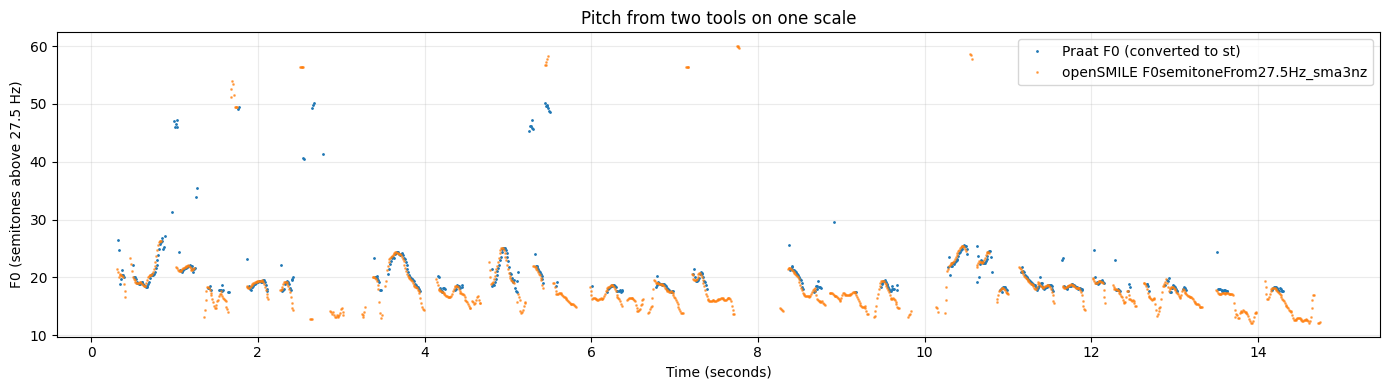

- Observed in attempt 1: both tools agreed on the rises near 0.9, 3.7, 4.9 and 10.5 s, but openSMILE had many points below ~17.4 st (= 75 Hz) where Praat had none; medians were Praat 19.21 st (83 Hz) vs openSMILE 17.53 st (76 Hz).

### Mistake realised

- The orange-only points below 17.4 st were the frames cut off by Praat's 75 Hz floor — Praat's median was higher only because it never saw the lowest frames.

### Correction made

- Same two-pass range correction as in 4.1.

**Change noticed**
- Medians now: Praat **17.81 st** vs openSMILE **17.53 st** → only 0.28 st apart (was 1.68 st).
- Praat now follows the low stretches down to ~12 st (≈ 55 Hz), e.g. near 2.6, 9.3 and 14.5 s.

**New interpretation**
- The two tools now overlap almost everywhere, so pitch is trustworthy wherever both report a value.
- Remaining disagreements:
  - openSMILE spikes to 50–60 st (1.7, 2.5, 5.5, 7.2, 7.7, 10.5 s) — openSMILE errors, not seen by Praat.
  - openSMILE-only points at 2.9–3.3 s and around 8 and 10 s, which fall inside the pauses → openSMILE marks some breath or pause frames as voiced.
- This explains the remaining voicing gap: openSMILE 70.1% vs Praat 61.4%.

# 7. Measurement reliability and limitations

- Each check is specific to one kind of measurement; no single threshold is used for everything.

| Check | Applies to | Why |
|---|---|---|
| Missing / non-finite values | All tables | `NaN`/`inf` break averages |
| Voicing coverage, Praat vs openSMILE | F0, HNR, jitter, shimmer | Voiced-only features rest on these frames |
| Octave jumps (frame-to-frame ratio > 1.8 or < 0.55) | Praat F0 | Signature of halving/doubling errors |
| Values within 5% of the pitch floor/ceiling | Praat F0 | The range is cutting off real values |
| `-200 dB` codes | Praat harmonicity | "Undefined", must not be averaged |
| Jitter/shimmer from running speech | Jitter, shimmer | They assume stable voicing |

In [ ]:
# (new) Reliability checks on the actual outputs
checks = []

def add_check(name, result, note):
    checks.append({"check": name, "result": result, "why it matters": note})

# 1. Missing / non-finite values
func_vals = functional_features.to_numpy(dtype=float)
lld_vals = lld_features.to_numpy(dtype=float)
add_check("Non-finite values in functionals", int((~np.isfinite(func_vals)).sum()),
          "Should be 0")
add_check("Non-finite values in LLDs", int((~np.isfinite(lld_vals)).sum()),
          "Should be 0 (openSMILE uses 0, not NaN, for unvoiced frames)")

# 2. Voicing coverage from both tools
praat_voiced = np.isfinite(pitch_values).mean()
smile_voiced = (lld_features[F0_LLD] > 0).mean()
add_check("Voiced frames, Praat", f"{100 * praat_voiced:.1f}%", "Share of frames with an F0 value")
add_check("Voiced frames, openSMILE", f"{100 * smile_voiced:.1f}%",
          "Large disagreement with Praat -> voicing decision is uncertain")

# 3. Octave-jump candidates in Praat F0 (consecutive voiced frames only)
ratio = pitch_values[1:] / pitch_values[:-1]
ratio = ratio[np.isfinite(ratio)]
n_jumps = int(((ratio > 1.8) | (ratio < 0.55)).sum())
add_check("Praat F0 octave-jump candidates", f"{n_jumps} of {len(ratio)} frame pairs",
          "Inspect these times; a few are common, many suggest a wrong pitch range")

# 4. F0 pinned near the range limits
valid_f0 = pitch_values[np.isfinite(pitch_values)]
near_limits = ((valid_f0 < F0_FLOOR * 1.05) | (valid_f0 > F0_CEILING * 0.95)).mean() if len(valid_f0) else np.nan
add_check("F0 within 5% of floor/ceiling", f"{100 * near_limits:.1f}%",
          "High share -> adjust pitch_floor / pitch_ceiling")

# 5. Praat harmonicity 'undefined' codes in the raw object
raw_hnr = np.array([harmonicity.get_value(t) for t in harm_times])
add_check("Praat HNR frames = -200 dB (undefined)", f"{100 * (raw_hnr <= -199).mean():.1f}%",
          "Already converted to NaN in Section 4.4")

# 6. Jitter/shimmer basis
add_check("Voiced LLD frames behind jitter/shimmer means", int((lld_features["jitterLocal_sma3nz"] > 0).sum()),
          "Computed from running speech, not a sustained vowel -> treat as rough")

reliability_table = pd.DataFrame(checks)
display(reliability_table)

,check,result,why it matters
0,Non-finite values in functionals,0,Should be 0
1,Non-finite values in LLDs,0,"Should be 0 (openSMILE uses 0, not NaN, for un..."
2,"Voiced frames, Praat",61.4%,Share of frames with an F0 value
3,"Voiced frames, openSMILE",70.1%,Large disagreement with Praat -> voicing decis...
4,Praat F0 octave-jump candidates,0 of 875 frame pairs,"Inspect these times; a few are common, many su..."
5,F0 within 5% of floor/ceiling,1.9%,High share -> adjust pitch_floor / pitch_ceiling
6,Praat HNR frames = -200 dB (undefined),33.6%,Already converted to NaN in Section 4.4
7,Voiced LLD frames behind jitter/shimmer means,698,"Computed from running speech, not a sustained ..."


**Change noticed after the corrections**

| Check | Attempt 1 | After correction | Reading |
|---|---|---|---|
| Non-finite values (functionals / LLDs) | 0 / 0 | 0 / 0 | OK |
| Voiced frames, Praat | 37.4% | **61.4%** | Recovered the low voice |
| Voiced frames, openSMILE | 70.1% | 70.1% | Unchanged (not affected by Praat settings) |
| Praat octave-jump candidates | 1 of 502 | **0 of 875** | Clean |
| F0 within 5% of floor/ceiling | 24.5% | **1.9%** | Range now fits the speaker |
| Praat HNR undefined (−200 dB) | 39.1% | **33.6%** | Matches the unvoiced share |
| Voiced frames behind jitter/shimmer | 698 | 698 | Running speech, not a steady vowel |

**Unreliable feature (Goal 1)**
- **Attempt 1:** Praat F0 was the unreliable feature — 24.5% of values pressed against the 75 Hz floor, only 37.4% voicing vs 70.1% in openSMILE, and openSMILE's 20th percentile (≈ 68 Hz) below the floor.
- **After correction:** Praat F0 passes every check. The feature now treated as unreliable is **openSMILE's F0 `amean` and slope functionals**: 30 spike frames at 50–60 st raised the mean from 17.72 st (cleaned) to 18.82 st and inflated the rising slope to 440.8 st/s; openSMILE also reports voicing inside pauses (70.1% vs 61.4%).

**Limitations**
- **Energy is not a voice activity detector.** Low intensity can be a quiet consonant; high energy can be noise. Any pause found from an energy threshold is approximate.
- **No speaking rate.** That needs a transcript or a defensible word/syllable count; `VoicedSegmentsPerSec` and `loudnessPeaksPerSec` are not substitutes.
- **Missing pitch is often correct** (unvoiced sounds, pauses), not a failure.
- **Recording conditions** (microphone, distance, room, compression, sample rate) change loudness, HNR and spectral balance, so features are compared only within comparable recordings.

## 7.1 Observations — Experiment 1

| Item | Notes |
|---|---|
| What the recording contains | One man reading for 14.84 s; three phrase pauses near 2–4 s, 7–9 s and 9–11 s; no clipping |
| What the plots and table show | Intensity 75–82 dB in speech, 40–50 dB in pauses; pitch ~55–128 Hz, median 76.9 Hz, rises near 0.9, 3.7, 4.9 and 10.5 s; declination within phrases |
| Do they agree? | Waveform, spectrogram, intensity and loudness agree on the pauses; Praat and openSMILE agree on the pitch contour after the range correction |
| Limitation / measurement error | Default settings (75 Hz pitch floor, 5500 Hz formant ceiling) were wrong for this low male voice; openSMILE F0 spikes still affect its mean and slope functionals |

## 7.2 Compact summary table

- Basic statistics for the main Praat measurements and every openSMILE functional, saved to CSV.

In [ ]:
summary_rows = []

def add_summary(name, values, unit):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]

    if len(valid) == 0:
        summary_rows.append({
            "measurement": name,
            "unit": unit,
            "valid_samples": 0,
            "mean": np.nan,
            "median": np.nan,
            "std": np.nan,
        })
        return

    summary_rows.append({
        "measurement": name,
        "unit": unit,
        "valid_samples": len(valid),
        "mean": np.mean(valid),
        "median": np.median(valid),
        "std": np.std(valid),
    })

add_summary("Praat pitch", pitch_values, "Hz")
add_summary("Praat intensity", intensity_values, "dB")
add_summary("Praat harmonicity", harm_values, "dB")

for col in functional_features.columns:
    values = functional_features[col].to_numpy(dtype=float)
    add_summary(f"openSMILE: {col}", values, "feature-specific")

summary_table = pd.DataFrame(summary_rows)

display(summary_table.head(20))
summary_table.to_csv(
    "/content/acoustic_measurement_summary.csv",
    index=False,
)

,measurement,unit,valid_samples,mean,median,std
0,Praat pitch,Hz,910,79.069569,76.923613,13.390595
1,Praat intensity,dB,1472,68.202992,72.947483,12.082414
2,Praat harmonicity,dB,984,10.290822,10.872712,5.907269
3,openSMILE: F0semitoneFrom27.5Hz_sma3nz_amean,feature-specific,1,18.818953,18.818953,0.000000
4,openSMILE: F0semitoneFrom27.5Hz_sma3nz_stddevNorm,feature-specific,1,0.369501,0.369501,0.000000
5,openSMILE: F0semitoneFrom27.5Hz_sma3nz_percent...,feature-specific,1,15.619290,15.619290,0.000000
6,openSMILE: F0semitoneFrom27.5Hz_sma3nz_percent...,feature-specific,1,17.534452,17.534452,0.000000
7,openSMILE: F0semitoneFrom27.5Hz_sma3nz_percent...,feature-specific,1,20.031361,20.031361,0.000000
8,openSMILE: F0semitoneFrom27.5Hz_sma3nz_pctlran...,feature-specific,1,4.412070,4.412070,0.000000
9,openSMILE: F0semitoneFrom27.5Hz_sma3nz_meanRis...,feature-specific,1,440.848328,440.848328,0.000000


**Observations**
- Praat pitch: mean 79.1 Hz, median 76.9 Hz over 910 frames. In attempt 1 the mean was 104.2 Hz and the median 83.4 Hz → the mean and median are now close because the spikes are gone.
- Praat intensity: mean 68.2 dB, median 72.9 dB over 1,472 frames.
- Praat harmonicity: mean 10.3 dB, median 10.9 dB over 984 frames (attempt 1: 6.0 / 6.9 dB over 902).
- openSMILE rows have `valid_samples = 1` and `std = 0`: there is one value per recording, so no spread can be computed. Variation inside the clip lives in the LLDs and the Praat time series.

# 8. Two-speaker conversational experiment (Goal 2)

**Research question:** What acoustic differences can be observed between consecutive speakers' turns, and what other factors might explain them?

- **Design:** descriptive and exploratory. No model, no significance tests, no claim that one speaker's prosody predicts or causes the next speaker's.
- **Turn** = a stretch of speech by one speaker; boundaries come from annotations, not from pitch or energy.
- **Overlap** = both speakers talking at once; features of an overlapped stretch mix two voices.
- **Backchannel** = a short response such as "yeah" or "mm-hm" while the other person keeps talking.

## 8.1 Recordings

| ID | Source | Licence / access | Length | How speakers & turns are established |
|---|---|---|---|---|
| `R1_pyannote` | `sample.wav` + `sample.rttm` from the [pyannote-audio](https://github.com/pyannote/pyannote-audio) repository (`tutorials/assets/`) | Repository MIT-licensed; origin and licence of the audio itself not stated | 30 s, 16 kHz | Reference RTTM annotation (`speaker90`, `speaker91`); whether it was made manually is not documented |
| `SBC006` "Cuz" | Santa Barbara Corpus of Spoken American English ([UCSB](https://linguistics.ucsb.edu/research/santa-barbara-corpus-spoken-american-english)) | CC BY-ND 3.0 US | first ~35 s | Times copied by hand from the transcript `SBC006.trn` |
| `SBC034` "What time is it now?" | same corpus | same | first ~28 s | Times copied by hand from `SBC034.trn` |

- **Recordings analysed in this run: only `R1_pyannote`.** The SBC audio is hosted on Box and was not added, so SBC006 and SBC034 were skipped (printed in 8.2). Their turn tables are kept for a future run.
- Fixed settings for every turn: pitch range 75–500 Hz, minimum turn length 1.0 s, at least 20 voiced Praat frames for pitch/HNR.

In [ ]:
# (new) Setup for the conversation experiment
import os
import urllib.request

CONV_DIR = "/content/conversations"
os.makedirs(CONV_DIR, exist_ok=True)

# Fixed settings, identical for every turn (and the same as Experiment 1)
PITCH_FLOOR = 75      # Hz
PITCH_CEILING = 500   # Hz
MIN_TURN_SEC = 1.0    # shorter turns stay in the table, but features are not computed
MIN_VOICED_FRAMES = 20  # fewer Praat voiced frames than this -> pitch/HNR marked unreliable

def download(url, path):
    """Download once; explain clearly if it fails."""
    if os.path.exists(path):
        return path
    try:
        urllib.request.urlretrieve(url, path)
    except Exception as err:
        raise RuntimeError(
            f"Download failed: {url}\n{err}\n"
            f"Check the internet connection, or download the file manually into {CONV_DIR}."
        )
    return path

### Recording R1 — turns from the RTTM annotation

- **RTTM** (Rich Transcription Time Marked) = plain-text annotation, one line per speech segment: column 4 = start (s), column 5 = duration (s), column 8 = speaker.
- Each annotated segment is treated as one turn.

In [ ]:
# (new) Recording R1: download audio + annotation, read the turns
PYANNOTE_BASE = "https://raw.githubusercontent.com/pyannote/pyannote-audio/develop/tutorials/assets/"
r1_wav = download(PYANNOTE_BASE + "sample.wav", f"{CONV_DIR}/R1_pyannote.wav")
r1_rttm = download(PYANNOTE_BASE + "sample.rttm", f"{CONV_DIR}/R1_pyannote.rttm")

rttm = pd.read_csv(r1_rttm, sep=r"\s+", header=None, usecols=[3, 4, 7],
                   names=["start", "duration", "speaker"])
r1_turns = pd.DataFrame({
    "recording_id": "R1_pyannote",
    "speaker": rttm["speaker"],
    "start": rttm["start"],
    "end": rttm["start"] + rttm["duration"],
})
display(r1_turns)

,recording_id,speaker,start,end
0,R1_pyannote,speaker90,6.69,7.12
1,R1_pyannote,speaker91,7.55,8.35
2,R1_pyannote,speaker90,8.32,10.02
3,R1_pyannote,speaker91,9.92,11.03
4,R1_pyannote,speaker90,10.57,14.70
5,R1_pyannote,speaker91,14.49,17.92
6,R1_pyannote,speaker90,18.05,21.49
7,R1_pyannote,speaker91,18.15,18.59
8,R1_pyannote,speaker91,21.78,28.50
9,R1_pyannote,speaker90,27.85,30.00


### SBC006 and SBC034 — manually supplied turn table

Rules used when copying from the transcripts:
- Each transcript line = an intonation unit with start/end time; a line with no speaker label continues the previous speaker.
- Consecutive lines by the same speaker are merged into one turn.
- Non-speech lines are left out: environment sounds (`>ENV`), breaths, throat-clearing.
- Overlapping speech is kept as written and measured later.
- These boundaries are **manual, not automatically verified**.

In [ ]:
# (new) Turn boundaries copied by hand from SBC006.trn and SBC034.trn (seconds)
sbc_turns = pd.DataFrame([
    # recording_id, speaker, start, end
    ("SBC006", "LENORE",  0.00,  2.29),
    ("SBC006", "ALINA",   1.69,  2.19),   # overlaps Lenore
    ("SBC006", "ALINA",   2.50,  4.10),
    ("SBC006", "LENORE",  4.10,  6.21),
    ("SBC006", "ALINA",   6.21, 12.98),
    ("SBC006", "LENORE", 12.98, 14.35),
    ("SBC006", "ALINA",  14.35, 18.68),
    ("SBC006", "LENORE", 18.68, 21.31),
    ("SBC006", "ALINA",  21.31, 34.55),   # Lenore's throat-clear at 28.20-28.45 left out

    ("SBC034", "KAREN",   4.475,  5.077),
    ("SBC034", "SCOTT",   5.077,  5.908),
    ("SBC034", "KAREN",   6.489, 10.399),
    ("SBC034", "SCOTT",  10.399, 12.008),
    ("SBC034", "KAREN",  13.158, 13.889),
    ("SBC034", "SCOTT",  13.889, 15.155),
    ("SBC034", "KAREN",  15.155, 19.574),
    ("SBC034", "SCOTT",  19.574, 21.174),
    ("SBC034", "KAREN",  20.268, 27.954),  # starts in overlap with Scott
], columns=["recording_id", "speaker", "start", "end"])

SBC_LOAD_SECONDS = 40   # only load the annotated excerpt, not the full ~20 min file

### 8.2 Loading the audio and building one turn table

In [ ]:
# (new) Load each recording at its own sample rate (mono)
def find_local_audio(rec_id):
    for ext in (".wav", ".mp3"):
        path = f"{CONV_DIR}/{rec_id}{ext}"
        if os.path.exists(path):
            return path
    return None

recordings = {}   # recording_id -> (audio array, sample rate)

y, sr = librosa.load(r1_wav, sr=None, mono=True)
recordings["R1_pyannote"] = (y.astype(np.float64), sr)

for rec_id in ["SBC006", "SBC034"]:
    path = find_local_audio(rec_id)
    if path is None:
        print(f"{rec_id}: no audio in {CONV_DIR} -> skipped (see the manual-download note in 8.1).")
        continue
    y, sr = librosa.load(path, sr=None, mono=True, duration=SBC_LOAD_SECONDS)
    recordings[rec_id] = (y.astype(np.float64), sr)

for rec_id, (y, sr) in recordings.items():
    print(f"{rec_id}: {sr} Hz, {len(y) / sr:.1f} s loaded")
    display(Audio(y, rate=sr))

SBC006: no audio in /content/conversations -> skipped (see the manual-download note in 8.1).
SBC034: no audio in /content/conversations -> skipped (see the manual-download note in 8.1).
R1_pyannote: 16000 Hz, 30.0 s loaded


In [ ]:
# (new) One table of all turns for the available recordings
all_turns = pd.concat([r1_turns, sbc_turns], ignore_index=True)
all_turns = all_turns[all_turns["recording_id"].isin(recordings)].copy()

bad = all_turns[all_turns["end"] <= all_turns["start"]]
if len(bad):
    raise ValueError(f"Turns with end <= start - fix the table:\n{bad}")

all_turns = all_turns.sort_values(["recording_id", "start"]).reset_index(drop=True)
all_turns["turn_id"] = all_turns.groupby("recording_id").cumcount() + 1
all_turns["duration"] = all_turns["end"] - all_turns["start"]

def overlap_with_other_speaker(row):
    """Seconds of this turn during which another speaker is also annotated."""
    others = all_turns[(all_turns["recording_id"] == row["recording_id"]) &
                       (all_turns["speaker"] != row["speaker"])]
    overlap = np.minimum(others["end"], row["end"]) - np.maximum(others["start"], row["start"])
    return overlap.clip(lower=0).sum()

all_turns["overlap_sec"] = all_turns.apply(overlap_with_other_speaker, axis=1)
display(all_turns.round(3))

,recording_id,speaker,start,end,turn_id,duration,overlap_sec
0,R1_pyannote,speaker90,6.69,7.12,1,0.43,0.00
1,R1_pyannote,speaker91,7.55,8.35,2,0.80,0.03
2,R1_pyannote,speaker90,8.32,10.02,3,1.70,0.13
3,R1_pyannote,speaker91,9.92,11.03,4,1.11,0.56
4,R1_pyannote,speaker90,10.57,14.70,5,4.13,0.67
5,R1_pyannote,speaker91,14.49,17.92,6,3.43,0.21
6,R1_pyannote,speaker90,18.05,21.49,7,3.44,0.44
7,R1_pyannote,speaker91,18.15,18.59,8,0.44,0.44
8,R1_pyannote,speaker91,21.78,28.50,9,6.72,0.65
9,R1_pyannote,speaker90,27.85,30.00,10,2.15,0.65


### Attempt 1 — initial assumption

- Every turn was measured between its annotated `start` and `end`, on the assumption that each turn holds one voice.
- Observed in attempt 1: 7 of 10 turns measured; 7 turns flagged `overlap` (0.2–0.7 s each); the largest difference between neighbours was **turn 4 → 5: −3.70 st**.

### Mistake realised

- The overlaps sat at the turn edges, where one speaker starts before the other finishes. Those edges contain **two voices**, so the turn's features mixed both speakers.
- Turn 4 was 1.11 s long with 0.56 s of overlap — half of it was not speaker91 alone.

### Correction made

- Overlapping edges are trimmed (next cell): if the other speaker is still talking at a turn's start, the start moves to when they stop; if the other speaker starts before the turn ends, the end moves earlier.
- The measurement cell now uses `start_clean` and `end_clean`.

In [ ]:
# Cut overlapping edges so each turn holds (mostly) one voice
def trim_overlap(row):
    start, end = row["start"], row["end"]
    others = all_turns[(all_turns["recording_id"] == row["recording_id"]) &
                       (all_turns["speaker"] != row["speaker"])]
    for _, o in others.iterrows():
        if o["start"] <= start < o["end"]:   # other speaker still talking when this turn starts
            start = o["end"]
        if o["start"] < end <= o["end"]:     # other speaker starts before this turn ends
            end = o["start"]
    return pd.Series({"start_clean": start, "end_clean": max(start, end)})

all_turns[["start_clean", "end_clean"]] = all_turns.apply(trim_overlap, axis=1)
all_turns["duration_clean"] = all_turns["end_clean"] - all_turns["start_clean"]
display(all_turns[["recording_id", "turn_id", "speaker", "start", "end", "start_clean", "end_clean", "duration_clean"]].round(2))

,recording_id,turn_id,speaker,start,end,start_clean,end_clean,duration_clean
0,R1_pyannote,1,speaker90,6.69,7.12,6.69,7.12,0.43
1,R1_pyannote,2,speaker91,7.55,8.35,7.55,8.32,0.77
2,R1_pyannote,3,speaker90,8.32,10.02,8.35,9.92,1.57
3,R1_pyannote,4,speaker91,9.92,11.03,10.02,10.57,0.55
4,R1_pyannote,5,speaker90,10.57,14.70,11.03,14.49,3.46
5,R1_pyannote,6,speaker91,14.49,17.92,14.70,17.92,3.22
6,R1_pyannote,7,speaker90,18.05,21.49,18.05,21.49,3.44
7,R1_pyannote,8,speaker91,18.15,18.59,21.49,21.49,0.00
8,R1_pyannote,9,speaker91,21.78,28.50,21.78,27.85,6.07
9,R1_pyannote,10,speaker90,27.85,30.00,28.50,30.00,1.50


**Observations**
- Turn 4: 1.11 s → **0.55 s** after trimming (now too short to measure).
- Turn 5: 4.13 s → 3.46 s; turn 9: 6.72 s → 6.07 s; turn 10: 2.15 s → 1.50 s.
- Turn 8 (the 0.44 s backchannel inside turn 7) → **0 s**.
- Turn 7 is unchanged: turn 8 sits fully inside it, so it cannot be trimmed from the edges. Turn 7 still contains 0.44 s of the other voice in its middle.

### 8.3 Turn-level features

For every turn (same settings everywhere):
- **openSMILE eGeMAPSv02 functionals** — six columns from the feature dictionary.
- **Praat check** — voiced-frame fraction and median F0 in Hz, as an independent check on pitch.

Reliability rules:
- `too_short`: under 1.0 s → no features (functionals of a few hundred ms are unstable).
- `few_voiced_frames`: fewer than 20 voiced Praat frames → pitch and HNR set to `NaN`.
- `overlap`: more than 0.2 s of annotated overlap with the other speaker.
- `f0_vs_own_median_st` = a turn's pitch minus the same speaker's median, because absolute pitch differences between two people mostly reflect anatomy.

In [ ]:
# (new) Features for one turn
SELECTED_FUNCTIONALS = {
    "F0semitoneFrom27.5Hz_sma3nz_amean":      "f0_mean_st",
    "F0semitoneFrom27.5Hz_sma3nz_stddevNorm": "f0_variability",
    "loudness_sma3_amean":                    "loudness_mean",
    "HNRdBACF_sma3nz_amean":                  "hnr_mean_db",
    "alphaRatioV_sma3nz_amean":               "alpha_ratio_db",
    "VoicedSegmentsPerSec":                   "voiced_segments_per_sec",
}

def measure_turn(y, sr, start, end):
    """Return (values, flags) for one turn. Unreliable values are NaN plus a flag."""
    values = {name: np.nan for name in SELECTED_FUNCTIONALS.values()}
    values.update(praat_voiced_fraction=np.nan, praat_median_f0_hz=np.nan)
    flags = []

    if end > len(y) / sr:
        return values, ["beyond_audio"]
    if end - start < MIN_TURN_SEC:
        return values, ["too_short"]

    segment = y[int(start * sr):int(end * sr)]

    # openSMILE functionals (same Smile object as Experiment 1)
    func = smile_functionals.process_signal(segment, sr)
    missing = [c for c in SELECTED_FUNCTIONALS if c not in func.columns]
    if missing:
        raise KeyError(f"Not in this eGeMAPS version: {missing}")
    for column, name in SELECTED_FUNCTIONALS.items():
        values[name] = float(func[column].iloc[0])

    # Praat voicing check on the same segment
    turn_pitch = parselmouth.Sound(segment, sampling_frequency=sr).to_pitch_cc(
        time_step=0.01, pitch_floor=PITCH_FLOOR, pitch_ceiling=PITCH_CEILING)
    f0 = turn_pitch.selected_array["frequency"]      # 0 = unvoiced frame
    voiced = f0[f0 > 0]
    values["praat_voiced_fraction"] = len(voiced) / max(len(f0), 1)
    if len(voiced) >= MIN_VOICED_FRAMES:
        values["praat_median_f0_hz"] = float(np.median(voiced))
    else:
        flags.append("few_voiced_frames")
        values["f0_mean_st"] = np.nan
        values["f0_variability"] = np.nan
        values["hnr_mean_db"] = np.nan

    return values, flags

In [ ]:
# (new) Measure every turn
rows = []
for _, turn in all_turns.iterrows():
    y, sr = recordings[turn["recording_id"]]
    values, flags = measure_turn(y, sr, turn["start_clean"], turn["end_clean"])
    if turn["overlap_sec"] > 0.2:
        flags.append("overlap")
    rows.append({**turn.to_dict(), **values, "flags": ", ".join(flags)})

turn_table = pd.DataFrame(rows)
turn_table["f0_vs_own_median_st"] = (
    turn_table["f0_mean_st"]
    - turn_table.groupby(["recording_id", "speaker"])["f0_mean_st"].transform("median")
)

print("Turns measured:", turn_table["f0_mean_st"].notna().sum(), "of", len(turn_table))
display(turn_table[[
    "recording_id", "turn_id", "speaker", "start_clean", "end_clean", "duration", "overlap_sec",
    "f0_mean_st", "f0_vs_own_median_st", "praat_median_f0_hz", "praat_voiced_fraction",
    "loudness_mean", "hnr_mean_db", "alpha_ratio_db", "flags",
]].round(2))

Turns measured: 6 of 10


,recording_id,turn_id,speaker,start_clean,end_clean,duration,overlap_sec,f0_mean_st,f0_vs_own_median_st,praat_median_f0_hz,praat_voiced_fraction,loudness_mean,hnr_mean_db,alpha_ratio_db,flags
0,R1_pyannote,1,speaker90,6.69,7.12,0.43,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too_short
1,R1_pyannote,2,speaker91,7.55,8.32,0.80,0.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too_short
2,R1_pyannote,3,speaker90,8.35,9.92,1.70,0.13,36.71,1.80,211.32,0.94,0.38,8.50,-10.36,
3,R1_pyannote,4,speaker91,10.02,10.57,1.11,0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"too_short, overlap"
4,R1_pyannote,5,speaker90,11.03,14.49,4.13,0.67,32.64,-2.27,176.29,0.77,0.28,8.59,-10.97,overlap
5,R1_pyannote,6,speaker91,14.70,17.92,3.43,0.21,34.79,1.00,186.34,0.62,0.29,9.09,-11.44,overlap
6,R1_pyannote,7,speaker90,18.05,21.49,3.44,0.44,34.90,-0.01,181.84,0.84,0.25,8.53,-10.64,overlap
7,R1_pyannote,8,speaker91,21.49,21.49,0.44,0.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"too_short, overlap"
8,R1_pyannote,9,speaker91,21.78,27.85,6.72,0.65,32.79,-1.00,181.30,0.77,0.30,9.91,-13.79,overlap
9,R1_pyannote,10,speaker90,28.50,30.00,2.15,0.65,34.91,0.01,214.06,0.92,0.41,9.59,-10.00,overlap


**Change noticed**

| Turn | Speaker | f0_mean_st attempt 1 → now | ≈ Hz now | Praat median Hz now |
|---|---|---|---|---|
| 3 | speaker90 | 36.85 → **36.71** | 230 | 211.3 |
| 4 | speaker91 | 37.01 → **too short** | — | — |
| 5 | speaker90 | 33.31 → **32.64** | 181 | 176.3 |
| 6 | speaker91 | 34.94 → **34.79** | 205 | 186.3 |
| 7 | speaker90 | 34.90 → 34.90 | 206 | 181.8 |
| 9 | speaker91 | 33.10 → **32.79** | 183 | 181.3 |
| 10 | speaker90 | 35.18 → **34.91** | 207 | 214.1 |

- Turns measured: **6 of 10** (attempt 1: 7). Turn 4 dropped out because half of it was overlap.
- Turn 5 dropped most (−0.67 st): its trimmed part was the loud, overlapped start.

**New interpretation**
- openSMILE (`f0_mean_st`, a mean) and Praat (median Hz) agree in direction for every turn; openSMILE is usually a little higher because a mean is pulled by high moments.
- Praat voiced fraction is 0.62–0.94 for the measured turns → enough voiced frames for pitch to be meaningful.
- HNR is ~8.5–9.9 dB for every turn and alpha ratio is lower for speaker91 (−11.4, −13.8 dB) than for speaker90 (−10.0 to −11.0 dB).
- Speaker91 now has only **2** measured turns, so its "own median" is the midpoint of two values and `f0_vs_own_median_st` is ±1.00 by construction.

**Remaining issues**
- The `overlap` flag is still computed from the **original** annotation, so trimmed turns keep a flag that no longer fully applies (only turn 7 truly still contains overlap).
- The `duration` column shows the original length; the measured length is `duration_clean`.

### 8.4 Turn timeline with Praat pitch

- Shaded bands = annotated turns (colour = speaker), brown where both overlap; dots = Praat F0 for the whole excerpt.
- This plot uses the **original** turn boundaries and the 75–500 Hz range.

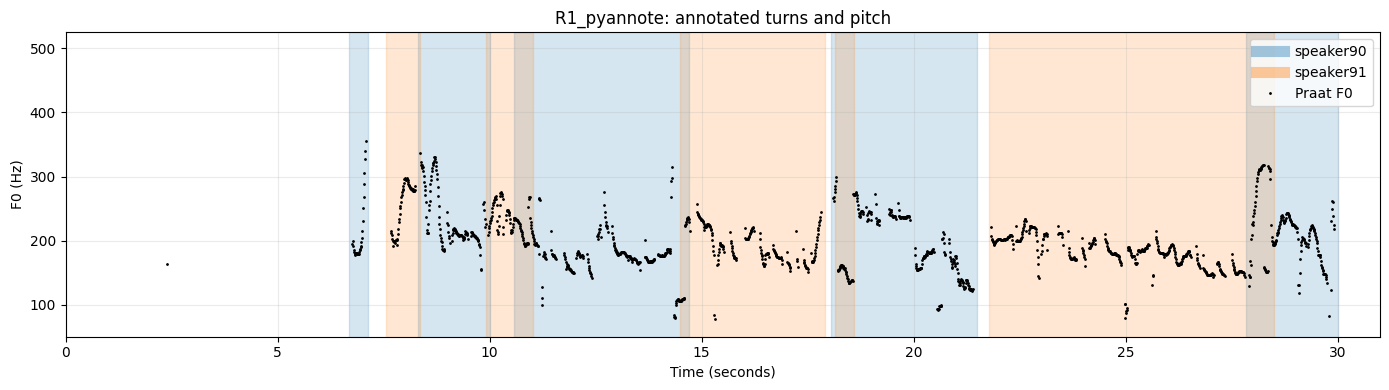

In [ ]:
# (new) One plot per recording: turns + F0 contour
for rec_id, (y, sr) in recordings.items():
    turns = turn_table[turn_table["recording_id"] == rec_id]
    rec_pitch = parselmouth.Sound(y, sampling_frequency=sr).to_pitch_cc(
        time_step=0.01, pitch_floor=PITCH_FLOOR, pitch_ceiling=PITCH_CEILING)
    f0 = rec_pitch.selected_array["frequency"].astype(float)
    f0[f0 == 0] = np.nan

    speakers = sorted(turns["speaker"].unique())
    colours = dict(zip(speakers, ["tab:blue", "tab:orange", "tab:green"]))

    fig, ax = plt.subplots(figsize=(14, 4))
    for spk in speakers:
        for _, t in turns[turns["speaker"] == spk].iterrows():
            ax.axvspan(t["start"], t["end"], color=colours[spk], alpha=0.18)
        ax.plot([], [], color=colours[spk], linewidth=8, alpha=0.4, label=spk)
    ax.plot(rec_pitch.xs(), f0, "k.", markersize=2, label="Praat F0")
    ax.set_xlim(0, turns["end"].max() + 1)
    ax.set_ylim(PITCH_FLOOR - 25, PITCH_CEILING + 25)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("F0 (Hz)")
    ax.set_title(f"{rec_id}: annotated turns and pitch")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

**Interpretation**
- The first 6.7 s of R1 are silence; speech starts at 6.69 s.
- Both speakers mostly sit at **150–250 Hz**, so pitch alone could not tell who is talking → speaker identity has to come from the annotation.
- Inside overlaps the pitch track can belong to either voice: at 18.2–18.6 s (turn 8 inside turn 7) dots at ~150 Hz sit below the ~250 Hz track around them.
- Dots near 100 Hz around 14.5 s and 25 s are likely octave errors downward (half the real pitch), or creak.

### 8.5 LLDs inside one turn

- The functionals reduce each turn to single numbers; the loudness and F0 LLDs of turn 5 show what those numbers hide.
- This plot uses turn 5's **original** boundaries (10.57–14.70 s), so it still includes the overlapped start.

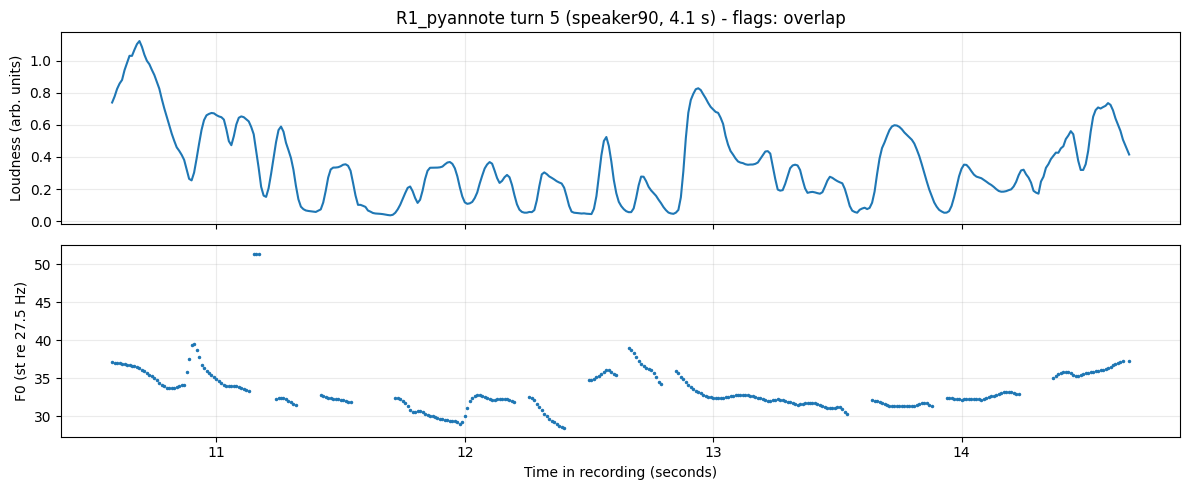

In [ ]:
# (new) Time-varying LLDs for one selected turn
RECORDING = "R1_pyannote"
TURN = 5

sel = turn_table[(turn_table["recording_id"] == RECORDING) & (turn_table["turn_id"] == TURN)]
if sel.empty:
    print("No such turn. Available:", turn_table.groupby("recording_id")["turn_id"].max().to_dict())
else:
    t = sel.iloc[0]
    y, sr = recordings[RECORDING]
    seg = y[int(t["start"] * sr):int(t["end"] * sr)]
    turn_lld = smile_lld.process_signal(seg, sr)
    tt = opensmile_frame_times(turn_lld) + t["start"]       # back to recording time

    f0_turn = turn_lld["F0semitoneFrom27.5Hz_sma3nz"].to_numpy(dtype=float)
    f0_turn[f0_turn == 0] = np.nan

    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axes[0].plot(tt, turn_lld["Loudness_sma3"])
    axes[0].set_ylabel("Loudness (arb. units)")
    axes[0].set_title(f"{RECORDING} turn {TURN} ({t['speaker']}, {t['duration']:.1f} s) - flags: {t['flags'] or 'none'}")
    axes[1].plot(tt, f0_turn, ".", markersize=3)
    axes[1].set_ylabel("F0 (st re 27.5 Hz)")
    axes[1].set_xlabel("Time in recording (seconds)")
    for ax in axes:
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    display(Audio(seg, rate=sr))

**Interpretation**
- Pitch starts near 37 st and drifts down to ~29 st by 12.3 s, then resets upward at ~12.6 s and ~14.4 s → **declination** within phrases.
- Loudness is highest (~1.1) at 10.6–10.8 s, which is the overlap with turn 4 — the same stretch the trimming removed.
- One point at ~51 st near 11.15 s is a tracking error.
- So one `f0_mean_st` value for this turn hides a 37 → 29 st fall and two resets; the mean depends on how many phrases the turn holds and where it was cut.

### 8.6 Comparing consecutive turns

- Only pairs where the speaker changes; Δ = next turn minus previous turn.
- `NaN` = at least one turn could not be measured reliably.

In [ ]:
# (new) Adjacent-turn comparison table
pairs = []
for rec_id, g in turn_table.groupby("recording_id"):
    g = g.sort_values("start").reset_index(drop=True)
    for i in range(1, len(g)):
        a, b = g.iloc[i - 1], g.iloc[i]
        if a["speaker"] == b["speaker"]:
            continue
        pairs.append({
            "recording": rec_id,
            "turns": f"{a['turn_id']} -> {b['turn_id']}",
            "speakers": f"{a['speaker']} -> {b['speaker']}",
            "durations_s": f"{a['duration']:.1f} / {b['duration']:.1f}",
            "delta_f0_st": b["f0_mean_st"] - a["f0_mean_st"],
            "delta_f0_vs_own_median_st": b["f0_vs_own_median_st"] - a["f0_vs_own_median_st"],
            "delta_loudness": b["loudness_mean"] - a["loudness_mean"],
            "delta_hnr_db": b["hnr_mean_db"] - a["hnr_mean_db"],
            "delta_alpha_ratio_db": b["alpha_ratio_db"] - a["alpha_ratio_db"],
            "flags": " | ".join(f for f in [a["flags"], b["flags"]] if f),
            "your_observation": "",
        })

comparison_table = pd.DataFrame(pairs)
display(comparison_table.round(2))

,recording,turns,speakers,durations_s,delta_f0_st,delta_f0_vs_own_median_st,delta_loudness,delta_hnr_db,delta_alpha_ratio_db,flags,your_observation
0,R1_pyannote,1 -> 2,speaker90 -> speaker91,0.4 / 0.8,NaN,NaN,NaN,NaN,NaN,too_short | too_short,
1,R1_pyannote,2 -> 3,speaker91 -> speaker90,0.8 / 1.7,NaN,NaN,NaN,NaN,NaN,too_short,
2,R1_pyannote,3 -> 4,speaker90 -> speaker91,1.7 / 1.1,NaN,NaN,NaN,NaN,NaN,"too_short, overlap",
3,R1_pyannote,4 -> 5,speaker91 -> speaker90,1.1 / 4.1,NaN,NaN,NaN,NaN,NaN,"too_short, overlap | overlap",
4,R1_pyannote,5 -> 6,speaker90 -> speaker91,4.1 / 3.4,2.16,3.27,0.01,0.50,-0.48,overlap | overlap,
5,R1_pyannote,6 -> 7,speaker91 -> speaker90,3.4 / 3.4,0.11,-1.01,-0.04,-0.56,0.80,overlap | overlap,
6,R1_pyannote,7 -> 8,speaker90 -> speaker91,3.4 / 0.4,NaN,NaN,NaN,NaN,NaN,"overlap | too_short, overlap",
7,R1_pyannote,9 -> 10,speaker91 -> speaker90,6.7 / 2.1,2.12,1.01,0.10,-0.31,3.79,overlap | overlap,


### 8.7 Interpreting turn differences

**Observable differences (after trimming)**

| Pair | Speakers | Durations (s) | Δ F0 (st) | Δ vs own median (st) | Δ loudness | Δ HNR (dB) | Δ alpha (dB) |
|---|---|---|---|---|---|---|---|
| 5 → 6 | 90 → 91 | 4.1 / 3.4 | +2.16 | +3.27 | +0.01 | +0.50 | −0.48 |
| 6 → 7 | 91 → 90 | 3.4 / 3.4 | +0.11 | −1.01 | −0.04 | −0.56 | +0.80 |
| 9 → 10 | 91 → 90 | 6.7 / 2.1 | +2.12 | +1.01 | +0.10 | −0.31 | +3.79 |

- Pairs 1→2, 2→3, 3→4, 4→5 and 7→8 are `NaN` because one turn was too short.
- 1 st is a small but audible step; 3–4 st is a clear jump.

**What changed from attempt 1**
- The attempt-1 "largest difference", turn 4 → 5 (−3.70 st), **disappeared**: after trimming, turn 4 is only 0.55 s. That difference was largely produced by overlap and turn length, not by the speakers.
- The largest remaining change is 5 → 6: +2.16 st, and +3.27 st relative to each speaker's own median.
- 9 → 10 shows +2.12 st together with the largest spectral-balance change (+3.79 dB alpha ratio).

**Alternative explanations considered**

| Factor | How it can create a difference |
|---|---|
| Different speakers (anatomy) | Absolute F0 and formants differ by speaker; `f0_vs_own_median_st` reduces this |
| Turn duration | Short turns give noisy functionals; long turns average over more variation (e.g. turn 5's declination) |
| Phonetic content | Vowels vs consonants and word choice change voicing, HNR and spectral balance |
| Turn type | Questions, backchannels, laughter, reading vs spontaneous speech (no transcript to check) |
| Recording conditions | Microphone distance and each person's position — a likely reason for speaker91's lower alpha ratio |
| Overlap | Two voices in one segment (still present in turn 7) |
| Annotation | Boundaries slightly off can include the other person or silence |

**What these measurements cannot establish**
- Emotion, intention, personality, dominance or rapport.
- That one speaker's prosody influenced the next (no causal or predictive design).
- Anything general about conversation — one 30 s recording with three usable pairs is an illustration, not a sample.
- Comparisons across recordings (different sample rates and setups).

# 9. Results, corrections log and conclusions

## 9.1 Experiment 1 report

In [ ]:
report = {
    "Research question": (
        "How do acoustic measurements vary throughout natural speech?"
    ),
    "Sample": audio_path,
    "Duration_seconds": round(duration, 2),
    "Sample_rate_Hz": sample_rate,
    "Median_Praat_F0_Hz": (
        round(float(np.nanmedian(pitch_values)), 2)
        if np.isfinite(pitch_values).any()
        else None
    ),
    "Praat_pitch_coverage_percent": round(
        100 * np.isfinite(pitch_values).mean(), 2
    ),
    "openSMILE_LLD_frame_count": len(lld_features),
    "openSMILE_functional_feature_count": len(
        functional_features.columns
    ),
    "Waveform_observation": "Fill in after inspection.",
    "Spectrogram_observation": "Fill in after inspection.",
    "Pitch_observation": "Fill in after inspection.",
    "Intensity_observation": "Fill in after inspection.",
    "Tool_difference_observation": "Fill in after comparison.",
    "Main_limitation": "Fill in after inspection.",
}

for key, value in report.items():
    print(f"{key}: {value}")

Research question: How do acoustic measurements vary throughout natural speech?
Sample: /root/.cache/librosa/5703-47212-0000.ogg
Duration_seconds: 14.84
Sample_rate_Hz: 22050
Median_Praat_F0_Hz: 76.92
Praat_pitch_coverage_percent: 61.44
openSMILE_LLD_frame_count: 1476
openSMILE_functional_feature_count: 88
Waveform_observation: Fill in after inspection.
Spectrogram_observation: Fill in after inspection.
Pitch_observation: Fill in after inspection.
Intensity_observation: Fill in after inspection.
Tool_difference_observation: Fill in after comparison.
Main_limitation: Fill in after inspection.


**Observations for the report**
- **Waveform:** three phrase pauses near 2–4, 7–9 and 9–11 s; peaks ±0.75, no clipping.
- **Spectrogram:** tightly packed harmonics below 500 Hz (low male voice), bending formant bands, fricative streaks up to 5 kHz.
- **Pitch:** median 76.9 Hz, 10th–90th percentile 64.8–97.8 Hz; rises on stressed words, declination within phrases.
- **Intensity:** 75–82 dB in speech vs 40–50 dB in pauses (~30–40 dB dynamic range); dips also inside words.
- **Tool differences:** voicing 61.4% (Praat) vs 70.1% (openSMILE); F0 medians 17.81 vs 17.53 st; HNR 10.3 dB (Praat) vs 1.38 dB (openSMILE).
- **Main limitation:** default analysis settings were made for an average voice; for this low male voice they cut off pitch, lowered HNR and scrambled formants until they were fitted.

## 9.2 Corrections log

| # | Where | Attempt 1 (initial assumption) | Mistake realised | Correction made | Change noticed |
|---|---|---|---|---|---|
| 1 | 4.1 Pitch | 75–500 Hz range | Floor above part of this voice; spikes at 380–500 Hz | Two-pass range: 53–129 Hz | Voiced 37.4% → 61.4%; median 83.4 → 76.9 Hz; floor pile-up 24.5% → 1.9% |
| 2 | 4.2 Intensity | `minimum_pitch` 75 Hz | Window not fitted to this voice | `F0_FLOOR` (53 Hz) | Small: mean 67.7 → 68.2 dB |
| 3 | 4.3 Formants | 5500 Hz ceiling, every frame | Female ceiling; formants measured in pauses and consonants | 5000 Hz; voiced + loud frames only | F1 now ~200–600 Hz instead of jumping to 1,500 Hz |
| 4 | 4.4 Harmonicity | `minimum_pitch` 75 Hz | Window too short for cycles under 75 Hz | `F0_FLOOR` (53 Hz) | Mean HNR 6.0 → 10.3 dB; "creaky voice" reading withdrawn |
| 5 | 4.5 Voice report | 75–500 Hz | Spike (417 Hz) and voice break inside the window | Fitted range | Max 417 → 128 Hz; jitter/shimmer unchanged → window content is the cause |
| 6 | 6.2 openSMILE F0 | Functionals used as given | 30 spike frames at 50–60 st | Removed frames > 12 st from median | Mean 18.82 → 17.72 st (81 → 76.5 Hz) |
| 7 | 6.3 Two tools | Praat median 19.21 st | Praat missed low frames | Range correction (#1) | Medians 0.28 st apart (was 1.68 st) |
| 8 | 8 Turns | Original turn boundaries | Overlapped edges mixed two voices | Trimmed overlap edges | Turn 4 → too short; the −3.70 st "largest difference" disappeared |



## 9.3 Experiment 2 research notes

| Item | Notes |
|---|---|
| Question | What acoustic differences can be observed between consecutive speakers' turns, and what other factors might explain them? |
| Recordings analysed | R1_pyannote only (30 s, 16 kHz); SBC006 and SBC034 not added |
| Turns measured vs flagged | 6 of 10 measured; 4 too short (turns 1, 2, 4 and the backchannel 8) |
| Observation 1 | Turn 5 → 6: +2.16 st (+3.27 st relative to each speaker's own median) |
| Observation 2 | Speaker91's alpha ratio is lower than speaker90's in every measured turn (−11.4 / −13.8 dB vs −10.0 to −11.0 dB) |
| Observation 3 | The −3.70 st difference seen in attempt 1 (turn 4 → 5) disappeared after trimming overlap |
| Alternative explanations | Turn length and declination (turn 5 falls 37 → 29 st), overlap, turn type, microphone position, phonetic content |
| Limitations | One 30 s recording; three usable pairs; annotation provenance unknown; no transcript; pitch range not fitted per speaker |
| Possible follow-up | Same two speakers, same microphone, many more turns; per-speaker pitch ranges; compare each turn with that speaker's own baseline over a longer recording |

## 9.4 Key takeaways
- Praat through Parselmouth gives Praat's own algorithms and numbers inside Colab — no desktop app needed.
- Waveform, spectrogram, pitch, intensity, formants and harmonicity each describe a different aspect of the audio.
- Default settings are a hypothesis: for this low male voice, the 75 Hz pitch floor and 5500 Hz formant ceiling produced wrong pitch, HNR and formants until they were fitted to the speaker.
- openSMILE LLDs keep frame-level variation; functionals give fixed-size summaries that lose temporal order, and their means are sensitive to tracking errors.
- Tools disagree because of algorithm, unit, setting and voicing decisions — they are compared on a common scale or by shape only.
- In conversations, overlap and turn length can create apparent differences between speakers; trimming overlap removed the largest attempt-1 difference.

# 10. Exporting the results

- Files are written to `/content/` and downloaded through the Colab browser download.

In [ ]:
praat_comparison.to_csv(
    "/content/praat_measurements_timeseries.csv",
    index=False,
)

print("Saved Praat time series.")

Saved Praat time series.


- The download cell expects three files (`opensmile_egemaps_functionals.csv`, `opensmile_egemaps_lld.csv`, `praat_pitch_timeseries.csv`) that were not written anywhere else, so the next cell writes them first, together with the Goal 1 and Goal 2 tables.

In [ ]:
# (new) Write the files the download cell expects, plus Experiment 2 outputs
functional_features.to_csv("/content/opensmile_egemaps_functionals.csv")
lld_features.to_csv("/content/opensmile_egemaps_lld.csv")
pd.DataFrame({"time_seconds": pitch_times, "praat_pitch_hz": pitch_values}).to_csv(
    "/content/praat_pitch_timeseries.csv", index=False)

feature_dictionary.to_csv("/content/feature_dictionary.csv", index=False)
reliability_table.to_csv("/content/reliability_checks.csv", index=False)
turn_table.to_csv("/content/conversation_turn_features.csv", index=False)
comparison_table.to_csv("/content/conversation_adjacent_turns.csv", index=False)

print("Saved CSV files to /content/")

Saved CSV files to /content/


In [ ]:
from google.colab import files

output_files = [
    "/content/opensmile_egemaps_functionals.csv",
    "/content/opensmile_egemaps_lld.csv",
    "/content/praat_pitch_timeseries.csv",
    "/content/praat_measurements_timeseries.csv",
    "/content/acoustic_measurement_summary.csv",
]

for path in output_files:
    files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# (new) Download the Goal 1 / Goal 2 files
from google.colab import files

for path in [
    "/content/feature_dictionary.csv",
    "/content/reliability_checks.csv",
    "/content/conversation_turn_features.csv",
    "/content/conversation_adjacent_turns.csv",
]:
    files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>